# 03c – XGBoost GPU, Logistic Regression L1 và Random Forest: 5 seed

**Bài toán:** phân loại sản phẩm bán dẫn thành **Pass = 0 / Fail = 1** từ 590 phép đo SECOM. Timestamp không phải đầu vào mô hình. Mục tiêu kinh doanh là giảm chi phí kỳ vọng theo ma trận kiểm tra/bỏ sót đã khai báo.

### Đọc nhanh trong 2 phút

1. Giữ đúng **4 bước preprocessing của notebook 02**, không thêm SelectKBest hoặc PCA vào mô hình.
2. Giữ một lần chia train/test 80/20: **train 1.253 mẫu, 83 Fail; test 314 mẫu, 21 Fail**.
3. Thử **XGBoost GPU, LR L1 và RF có trọng số lớp**, với 5 seed định trước: **13, 42, 123, 2024, 2026**. Các seed dùng lại cùng test.
4. Với từng mô hình/seed, **AP OOF-train chọn cấu hình**; **chi phí OOF-train chọn ngưỡng**. Chi phí chính là $(TP+FP+10FN)/N$.
5. Đóng băng cả 15 policy và lựa chọn phát triển trước khi chấm test. Báo đủ 15 run, không chọn seed đẹp nhất.
6. Phân biệt **điểm OOF dùng để chọn** với **kết quả test**. Thiết kế 03c **không phải nested CV** như notebook 03b.

**Đường đọc:** mục 1 để hiểu chi phí; mục 5–7 để hiểu pipeline và mô hình; mục 10–11 để hiểu kết quả; mục 15–16 để hiểu early stopping và ngưỡng. Phần code ngay sau mỗi lời giải thích thực hiện đúng bước đó.

Các chỉ số là **số đo thực nghiệm**, không phải số giả lập. Chi phí tương đối là **giả định của thử nghiệm**, chưa phải số tiền thực tế của doanh nghiệp. Kết quả lưu riêng ở `artifacts/three_model_five_seeds/` và `figures/three_model_five_seeds/`; notebook không tự thay thế 03/03b hay mô hình dashboard.


## 1. Ma trận chi phí: đang tối ưu điều gì?

Quy ước lớp dương là **Fail = 1**. Cần phân biệt rõ:

| Thực tế | Phân loại Pass | Phân loại Fail |
|---|---|---|
| Pass | **TN:** sản phẩm tốt được nhận đúng | **FP:** sản phẩm tốt bị báo lỗi nhầm |
| Fail | **FN:** sản phẩm lỗi bị bỏ sót | **TP:** sản phẩm lỗi được phát hiện đúng |

Một sản phẩm được gán Fail sẽ được kỹ sư kiểm tra lại, dù cảnh báo đúng hay nhầm. Chuẩn hóa **một lần kiểm tra = 1 đơn vị chi phí**; giả định **một lần bỏ sót Fail = 10 đơn vị**. Ma trận chi phí vì thế là TN = 0, FP = 1, TP = 1, FN = 10.

Với $N=TP+FP+FN+TN$ sản phẩm:

$$
\text{Số kiểm tra}=TP+FP,\qquad
\text{Tổng chi phí}=TP+FP+10FN.
$$

$$
EC=\frac{TP+FP+10FN}{N},\qquad
\text{Chi phí/1.000 sản phẩm}=1000\,EC.
$$

**EC càng thấp càng tốt.** EC = 0,5 nghĩa là 0,5 **đơn vị chi phí trên mỗi sản phẩm**, không phải sai 50%. Con số FN = 10 trong ma trận nói về **chi phí của mỗi lần bỏ sót**, không nói phải bỏ sót 10 sản phẩm hay 10% sản phẩm. Chi phí bỏ sót cao hơn tạo động lực chấp nhận thêm lượt kiểm tra để giảm FN.

Code cũng báo `emc_error_only`:

$$
EMC_{error\ only}=\frac{FP+10FN}{N}.
$$

Công thức này chỉ tính hai loại sai và bỏ qua công kiểm tra TP; nó **không phải tiêu chí chi phí chính** của notebook. Không dùng hai cột chi phí thay cho nhau. Không tự đổi ma trận hoặc ngưỡng sau khi xem kết quả test.

Giả định vận hành là kiểm tra lại phát hiện được lỗi. Chi phí FN là tổn thất kỳ vọng còn lại ở bước này, có xét QC tiếp theo; FN không tự động đồng nghĩa sản phẩm lỗi đã giao cho khách hàng. **Chưa có chi phí thật hoặc yêu cầu Recall tối thiểu từ doanh nghiệp.**

Hai cách xếp hạng được báo riêng: **chi phí** đo đánh đổi vận hành ở ngưỡng đã chọn; **AP** đo khả năng đưa Fail lên vị trí ưu tiên trên nhiều ngưỡng. Precision, Recall, F1, BER và TP/FP/FN/TN giúp giải thích vì sao hai bảng có thể xếp hạng khác nhau.


## 2. Thiết kế thí nghiệm: một test cố định, năm seed

**Split seed = 42** quyết định sản phẩm nào thuộc train/test. **Experiment seed = 13, 42, 123, 2024, 2026** thay đổi cách chia fold trong train và tính ngẫu nhiên của thuật toán. Ba mô hình dùng cùng các fold của mỗi seed để so sánh nhất quán.

### Giai đoạn phát triển – chỉ dùng train

1. Chia train thành **5 fold stratified**. Với mỗi cấu hình, dùng 4 fold fit toàn bộ preprocessing + mô hình và dự đoán fold còn lại.
2. Ghép dự đoán thành **OOF (out-of-fold)**: mỗi mẫu train có một score do mô hình không được fit trên mẫu đó tạo ra. Tính AP trên toàn bộ score OOF gộp, không lấy trung bình AP đã làm tròn của các fold.
3. Trong mỗi họ mô hình/seed, chọn cấu hình có **AP OOF cao nhất**; nếu bằng AP thì chọn **EC OOF thấp hơn**, sau đó candidate ID để kết quả xác định.
4. Với cấu hình đó, chọn ngưỡng làm chi phí OOF thấp nhất. Fit lại trên toàn bộ train và giữ nguyên ngưỡng.
5. Sau đủ 15 run, chọn **development winner** theo EC OOF trung bình thấp nhất qua 5 seed; nếu hòa thì AP cao hơn, rồi tên mô hình. Ghi mọi policy và lựa chọn này vào `frozen_policies_before_test.json` **trước khi chấm test**.

Đây là **quy trình hai bước đã khai báo: chọn cấu hình theo AP trước, chọn ngưỡng theo chi phí sau**; không tối thiểu hóa chi phí chung trên toàn bộ lưới cấu hình. Một cấu hình có AP thấp hơn vẫn có thể có ngưỡng với chi phí thấp hơn, nhưng không được ưu tiên trừ trường hợp hòa AP theo quy tắc trên.

### Giai đoạn test – chỉ áp dụng các policy đã đóng băng

Đánh giá đủ 15 policy trên cùng test, rồi báo từng run và mean ± std. Không dùng test để chọn cấu hình, early stopping, ngưỡng hoặc seed. Test trong dự án đã từng được xem ở các thử nghiệm trước; đây không phải một tập kiểm định mù hoàn toàn mới cho toàn bộ quá trình nghiên cứu.

**03c không dùng nested CV.** Score OOF vừa tham gia chọn cấu hình/ngưỡng vừa được báo ở phần phát triển, nên điểm OOF có thể lạc quan. Test đo các policy đã chốt, còn việc xác nhận tổng quát hóa cần dữ liệu giữ riêng mới phù hợp.

Test chỉ có **21 Fail**: mỗi ca đổi Recall khoảng $1/21=4,76$ điểm phần trăm. Năm seed vẫn dự đoán lại **cùng 314 sản phẩm**, không tạo ra năm test độc lập hoặc 1.570 sản phẩm mới. Mean ± std mô tả độ nhạy với seed, không phải khoảng tin cậy về mọi sản phẩm tương lai.

Riêng XGBoost có pilot early stopping **bên trong phần train của từng fold**, sau đó refit mới; mục 15 giải thích chi tiết. Boosting round của XGBoost, iteration của LR và số cây RF là ba khái niệm khác nhau; notebook không có mạng neural hay epoch.


## 3. Nguồn phương pháp, file cần có và cách chạy

- Bốn bước preprocessing lấy đúng cấu trúc của [02_preprocessing.ipynb](./02_preprocessing.ipynb).
- Cách tổ chức phân loại/đánh giá kế thừa [03_modeling.ipynb](./03_modeling.ipynb) và [04_evaluation.ipynb](./04_evaluation.ipynb), với thiết kế 3 mô hình, L1, GPU và 5 seed được khai báo riêng ở đây.
- Các hàm thực thi nằm trong [secom_three_model_experiment.py](./secom_three_model_experiment.py); cần giữ cùng [secom_utils.py](./secom_utils.py) và [secom_preprocessing.py](./secom_preprocessing.py) ở thư mục gốc.

**Tham khảo Kaggle chưa xác minh:** [industrial-ai-test của thienphuc2201](https://www.kaggle.com/code/thienphuc2201/industrial-ai-test) không truy cập được trong môi trường chuẩn bị notebook. Chưa lấy được mã nguồn, nên **không tuyên bố đã tái lập hay áp dụng các bước cụ thể từ notebook Kaggle**. Cần đối chiếu riêng nếu có bản mã nguồn truy cập được.

Tài liệu chính thức: [XGBoost GPU](https://xgboost.readthedocs.io/en/stable/gpu/index.html), [XGBClassifier/early stopping](https://xgboost.readthedocs.io/en/stable/python/python_api.html#xgboost.XGBClassifier), [LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html), [AP](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html), [Precision–Recall curve](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.precision_recall_curve.html).

### Chuẩn bị trước khi Run All

1. Có đúng hai file `data/secom/secom.data` và `data/secom/secom_labels.data`. Các file `.data` bị Git bỏ qua, nên pull repo không tự mang theo dữ liệu.
2. Mở notebook từ thư mục dự án hoặc thư mục con; dùng kernel Python đã cài các thư viện trong `requirements.txt` và XGBoost.
3. Lần chạy được lưu dùng **Python 3.11, scikit-learn 1.9.1, XGBoost 3.2.0**. Trong môi trường Python riêng của mình, có thể cài:

```powershell
python -m pip install -r requirements.txt "scikit-learn==1.9.1" "xgboost==3.2.0"
```

4. Chọn kernel đúng môi trường rồi **Restart Kernel and Run All**. Chạy lại sẽ fit lại nhiều mô hình và ghi lại kết quả trong các thư mục riêng của 03c.

XGBoost được yêu cầu thực sự chạy trên **NVIDIA GPU hỗ trợ CUDA**, với driver/build phù hợp. Lần chạy này được ghi nhận trên **RTX 3050 Laptop GPU**, thiết bị mô hình `cuda:0`. LR L1 và RF chạy **CPU**. Nếu không có CUDA phù hợp, helper báo lỗi thay vì âm thầm coi kết quả CPU là kết quả GPU. Muốn làm bản CPU cần khai báo một thí nghiệm khác.

Output đã nhúng trong notebook có thể đọc mà chưa chạy lại. CSV, model và PNG riêng được sinh khi chạy và không mặc định có đủ trong mọi bản pull. Nếu thiếu module, kiểm tra các file hỗ trợ; nếu thiếu thư viện, kiểm tra đúng kernel. Đối chiếu `run_metadata.json` khi kết quả khác vì phiên bản, dữ liệu hoặc cấu hình.


In [1]:
import json
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import (
    average_precision_score, precision_recall_curve, auc,
    confusion_matrix, ConfusionMatrixDisplay,
)

project_candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(
    (path for path in project_candidates
     if (path / "secom_utils.py").is_file()
     and (path / "secom_preprocessing.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Chạy notebook từ thư mục dự án SECOM hoặc một thư mục con.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from secom_utils import load_secom, get_split, MISSING_THRESHOLD
from secom_preprocessing import MissingRateSelector
from secom_three_model_experiment import run_experiment, MODEL_NAMES

SPLIT_SEED = 42
EXPERIMENT_SEEDS = (13, 42, 123, 2024, 2026)
DISPLAY_SEED = 42  # Chọn trước để minh họa; không phải seed có điểm cao nhất.
OUTPUT_DIR = PROJECT_ROOT / "artifacts" / "three_model_five_seeds"
FIGURE_DIR = PROJECT_ROOT / "figures" / "three_model_five_seeds"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 90)
plt.rcParams.update({"font.family": "DejaVu Sans", "figure.dpi": 120})
print("Project:", PROJECT_ROOT)
print("Python:", sys.executable)
print("Split seed:", SPLIT_SEED, "| Experiment seeds:", EXPERIMENT_SEEDS)
print("Output:", OUTPUT_DIR)

Project: D:\AI_Bussiness_Huflit\Đồ án cuối
Python: C:\Users\ductr\AppData\Local\Programs\Python\Python311\python.exe
Split seed: 42 | Experiment seeds: (13, 42, 123, 2024, 2026)
Output: D:\AI_Bussiness_Huflit\Đồ án cuối\artifacts\three_model_five_seeds


## 4. Nạp dữ liệu và kiểm tra lần chia cố định

`load_secom` đọc 590 cột số, đổi nhãn gốc `-1/1` thành Pass = 0 / Fail = 1 và trả thêm timestamp. Notebook không ghép timestamp vào X. Đây là **phân loại nhãn sản phẩm từ các phép đo**, không phải mô hình dự báo chuỗi thời gian.

| Phần dữ liệu | Sản phẩm | Pass | Fail | Vai trò |
|---|---:|---:|---:|---|
| Toàn bộ | 1.567 | 1.463 | 104 | Nạp và chia tập |
| Train cố định | 1.253 | 1.170 | 83 | CV, chọn cấu hình/ngưỡng, refit |
| Test cố định | 314 | 293 | 21 | Chấm 15 policy đã đóng băng |

`get_split(..., seed=42)` gọi `train_test_split` với `stratify=y` ở bên trong để giữ tỷ lệ lớp gần giống giữa train và test. **Stratified không làm hai lớp có số mẫu bằng nhau.** Các assertion kiểm tra số dòng, số cột, nhãn và train/test không trùng chỉ số sản phẩm.

Tỷ lệ Fail test là $21/314\approx6,69\%$. Luôn gán Pass vẫn có Accuracy $293/314\approx93,31\%$, nhưng Recall Fail = 0. Đây là lý do cần báo chi phí và chỉ số của lớp Fail thay vì chỉ nhìn Accuracy. Các bước EDA/PCA tiếp theo chỉ được fit trên train.


In [2]:
X_raw, y_raw, _timestamp = load_secom()
train_idx, test_idx = get_split(y_raw, test_size=0.20, seed=SPLIT_SEED)
X_train = X_raw.iloc[train_idx].copy()
y_train = y_raw.iloc[train_idx].copy()
X_test = X_raw.iloc[test_idx].copy()
y_test = y_raw.iloc[test_idx].copy()

assert X_raw.shape == (1567, 590)
assert X_train.index.equals(y_train.index) and X_test.index.equals(y_test.index)
assert set(train_idx).isdisjoint(set(test_idx))
assert (len(y_train), int(y_train.sum()), len(y_test), int(y_test.sum())) == (1253, 83, 314, 21)
split_summary = pd.DataFrame([
    {"Tập": name, "Số sản phẩm": len(labels),
     "Pass": int((labels == 0).sum()), "Fail": int((labels == 1).sum()),
     "Tỷ lệ Fail": float(labels.mean())}
    for name, labels in [("Train", y_train), ("Test cố định", y_test)]
])
display(split_summary)
print(f"Luôn đoán Pass trên test: Accuracy={(y_test == 0).mean():.4f}, Recall Fail=0.")
print(f"Luôn Pass: chi phí={10 * y_test.mean():.4f}/sản phẩm; kiểm tra tất cả: chi phí=1/sản phẩm.")

,Tập,Số sản phẩm,Pass,Fail,Tỷ lệ Fail
0,Train,1253,1170,83,0.066241
1,Test cố định,314,293,21,0.066879


Luôn đoán Pass trên test: Accuracy=0.9331, Recall Fail=0.
Luôn Pass: chi phí=0.6688/sản phẩm; kiểm tra tất cả: chi phí=1/sản phẩm.


## 5. Bốn bước preprocessing: xử lý gì và học từ đâu?

Pipeline giữ đúng thứ tự của notebook 02:

```text
590 cột thô → lọc cột thiếu >70% → điền median → bỏ cột hằng → StandardScaler
            → XGBoost / LR L1 / RF
```

| Bước | Cách tính trên phần đang fit | Mục đích |
|---|---|---|
| `MissingRateSelector(0.70)` | Với cột j, $m_j=\#NaN_j/n$. Loại nếu $m_j>0,70$; đúng 70% vẫn được giữ. | Tránh giữ cột mà phần lớn thông tin đã thiếu. |
| `SimpleImputer(median)` | Lấy trung vị các giá trị quan sát của từng cột; dùng trung vị đó thay NaN. | Có đầu vào đầy đủ, ít bị giá trị cực trị kéo lệch hơn dùng trung bình. |
| `VarianceThreshold(0)` | $v_j=\frac1n\sum_i(x_{ij}-\bar x_j)^2$ sau impute; loại cột có phương sai bằng 0. | Cột hằng không tạo khác biệt giữa các mẫu; cột gần hằng không tự bị loại. |
| `StandardScaler()` | $z_{ij}=(x_{ij}-\mu_j)/\sigma_j$, với mean/std học từ phần train; std của scaler dùng quy ước `ddof=0`. | Đưa các thang đo về mức có thể so sánh, đặc biệt hữu ích cho LR và regularization. |

Khi đánh giá một fold, median, mặt nạ giữ cột, mean và std chỉ được học từ **train của fold**. Fold validation/test dùng lại các tham số ấy, không được fit riêng. Tập validation/test không bắt buộc có mean = 0 và std = 1 sau transform. Scaler cũng không tự xóa outlier hay biến mọi phân bố thành phân bố chuẩn.

Code bên dưới fit một pipeline riêng trên **toàn bộ train chỉ để chẩn đoán/PCA**. Ma trận minh họa này **không được đưa vào CV**. Helper tạo preprocessor mới cho mỗi lần fit; pilot early stopping của XGBoost còn fit preprocessor chỉ trên train-pilot.

Lần chẩn đoán hiện tại: khoảng **4,58% ô thiếu**, **8 cột thiếu >70%**, loại **116 cột hằng** sau impute, còn **466 cột**; có **320 cặp** với $|r_{Pearson}|>0,95$. Đây là số đo trên toàn bộ train. Số cột trong một fold có thể khác vì được học lại.

**Không có SelectKBest, không có bước PCA trong classifier.** L1 làm thưa hệ số trong quá trình LR học, không phải một bước chọn cột riêng trước mọi mô hình. Heatmap chọn tối đa 20 cột để vẽ theo tương quan trên train, không thay tập đặc trưng dùng huấn luyện. Tổng cặp tương quan đếm nửa trên ma trận, bỏ đường chéo, không đếm đôi.

Thiếu dữ liệu, cột tương quan và ít Fail là các đặc điểm cần lưu ý, chưa chứng minh dữ liệu “xấu”, không thể phân loại, hoặc cảm biến nào gây lỗi sản phẩm.


,Chỉ số train,Giá trị
0,Tỷ lệ ô thiếu trên 590 cột thô,0.045813
1,Số cột thiếu hơn 70%,8.000000
2,Số cột sau lọc missing,582.000000
3,Số cột hằng bị loại sau impute,116.000000
4,"Số cột cuối sau 4 bước, không SelectKBest",466.000000
5,"Số cặp cột sau preprocessing có |r| > 0,95",320.000000
6,Số sản phẩm Fail,83.000000


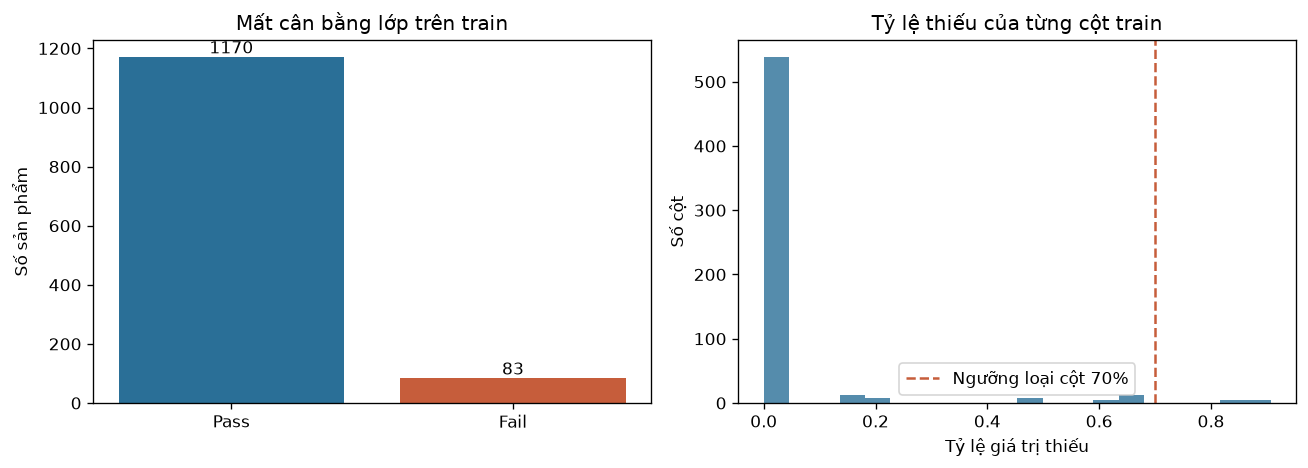

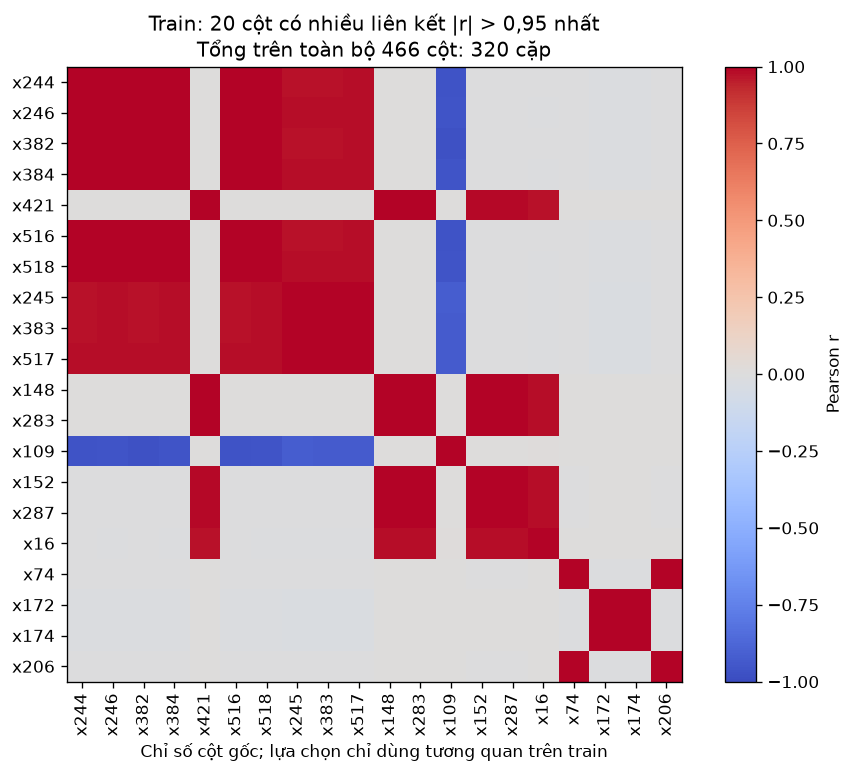

In [3]:
diagnostic_preprocessing = Pipeline([
    ("missing_rate", MissingRateSelector(threshold=MISSING_THRESHOLD)),
    ("imputer", SimpleImputer(strategy="median")),
    ("constant", VarianceThreshold(threshold=0.0)),
    ("scaler", StandardScaler()),
])
X_train_diagnostic = diagnostic_preprocessing.fit_transform(X_train)
missing_rates = X_train.isna().mean(axis=0)
missing_selector = diagnostic_preprocessing.named_steps["missing_rate"]
constant_selector = diagnostic_preprocessing.named_steps["constant"]
n_after_missing = int(missing_selector.get_support().sum())
n_after_constant = int(constant_selector.get_support().sum())
correlation_matrix = np.corrcoef(X_train_diagnostic, rowvar=False)
upper_correlations = correlation_matrix[np.triu_indices_from(correlation_matrix, k=1)]
finite_correlations = upper_correlations[np.isfinite(upper_correlations)]
high_correlation_pairs = int((np.abs(finite_correlations) > 0.95).sum())

assert np.isfinite(X_train_diagnostic).all()
assert X_train_diagnostic.shape == (len(y_train), n_after_constant)
diagnostics = pd.DataFrame([
    {"Chỉ số train": "Tỷ lệ ô thiếu trên 590 cột thô", "Giá trị": float(X_train.isna().to_numpy().mean())},
    {"Chỉ số train": "Số cột thiếu hơn 70%", "Giá trị": int((missing_rates > MISSING_THRESHOLD).sum())},
    {"Chỉ số train": "Số cột sau lọc missing", "Giá trị": n_after_missing},
    {"Chỉ số train": "Số cột hằng bị loại sau impute", "Giá trị": n_after_missing - n_after_constant},
    {"Chỉ số train": "Số cột cuối sau 4 bước, không SelectKBest", "Giá trị": n_after_constant},
    {"Chỉ số train": "Số cặp cột sau preprocessing có |r| > 0,95", "Giá trị": high_correlation_pairs},
    {"Chỉ số train": "Số sản phẩm Fail", "Giá trị": int(y_train.sum())},
])
display(diagnostics)
diagnostics.to_csv(OUTPUT_DIR / "train_data_diagnostics.csv", index=False, encoding="utf-8-sig")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(["Pass", "Fail"], [(y_train == 0).sum(), (y_train == 1).sum()], color=["#2A6F97", "#C65D3B"])
axes[0].set(title="Mất cân bằng lớp trên train", ylabel="Số sản phẩm")
for index, count in enumerate([(y_train == 0).sum(), (y_train == 1).sum()]):
    axes[0].text(index, count, str(count), ha="center", va="bottom")
axes[1].hist(missing_rates, bins=20, color="#2A6F97", alpha=0.8)
axes[1].axvline(MISSING_THRESHOLD, color="#C65D3B", linestyle="--", label="Ngưỡng loại cột 70%")
axes[1].set(title="Tỷ lệ thiếu của từng cột train", xlabel="Tỷ lệ giá trị thiếu", ylabel="Số cột")
axes[1].legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "train_class_balance_and_missingness.png", dpi=170, bbox_inches="tight")
plt.show()

# Chỉ minh họa tính dư thừa trên train, không thay đổi tập đặc trưng mô hình.
original_positions = np.flatnonzero(missing_selector.get_support())[constant_selector.get_support()]
original_ids = X_train.columns.to_numpy()[original_positions]
assert len(original_ids) == correlation_matrix.shape[0]
strong = np.isfinite(correlation_matrix) & (np.abs(correlation_matrix) > 0.95)
np.fill_diagonal(strong, False)
total_pairs = int(np.triu(strong, k=1).sum())
assert total_pairs == high_correlation_pairs
degrees = strong.sum(axis=1)
ranked = np.lexsort((original_ids, -degrees))
chosen = ranked[degrees[ranked] > 0][:20]
if len(chosen) == 0:
    print("Train không có cặp cột nào có |r| > 0,95.")
else:
    original_labels = [f"x{int(original_ids[i])}" for i in chosen]
    fig, ax = plt.subplots(figsize=(8, 6.5))
    heatmap = ax.imshow(correlation_matrix[np.ix_(chosen, chosen)], cmap="coolwarm", vmin=-1, vmax=1)
    ax.set_xticks(range(len(chosen)), original_labels, rotation=90)
    ax.set_yticks(range(len(chosen)), original_labels)
    ax.set_title(
        f"Train: {len(chosen)} cột có nhiều liên kết |r| > 0,95 nhất\n"
        f"Tổng trên toàn bộ {len(original_ids)} cột: {total_pairs} cặp"
    )
    ax.set_xlabel("Chỉ số cột gốc; lựa chọn chỉ dùng tương quan trên train")
    fig.colorbar(heatmap, ax=ax, label="Pearson r")
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / "train_high_correlation_heatmap.png", dpi=170, bbox_inches="tight")
    plt.show()


## 6. PCA trên train: xem cấu trúc dữ liệu bằng hình chiếu 2D

PCA tạo các trục là tổ hợp tuyến tính của đặc trưng, sao cho giữ nhiều phương sai nhất. Ở đây PCA chỉ fit trên train sau bốn bước preprocessing, không dùng nhãn để tìm trục; nhãn chỉ dùng tô màu các điểm trong hình.

`explained_variance_ratio_` cho biết tỷ lệ phương sai được mỗi trục giữ lại. Tổng của PC1 và PC2 được ghi trong tiêu đề hình. Đây là tỷ lệ phương sai của đặc trưng, **không phải Accuracy, tỷ lệ giải thích nguyên nhân lỗi hay tỷ lệ mẫu phân loại đúng**.

Hai lớp chồng lên nhau trong hình chiếu 2D không chứng minh chúng không thể phân tách trong không gian 466 đặc trưng. Ngược lại, nhìn có cụm cũng chưa chứng minh classifier tổng quát hóa tốt. Hai thành phần PCA **không được đưa làm đầu vào** XGBoost/LR/RF trong thử nghiệm này.


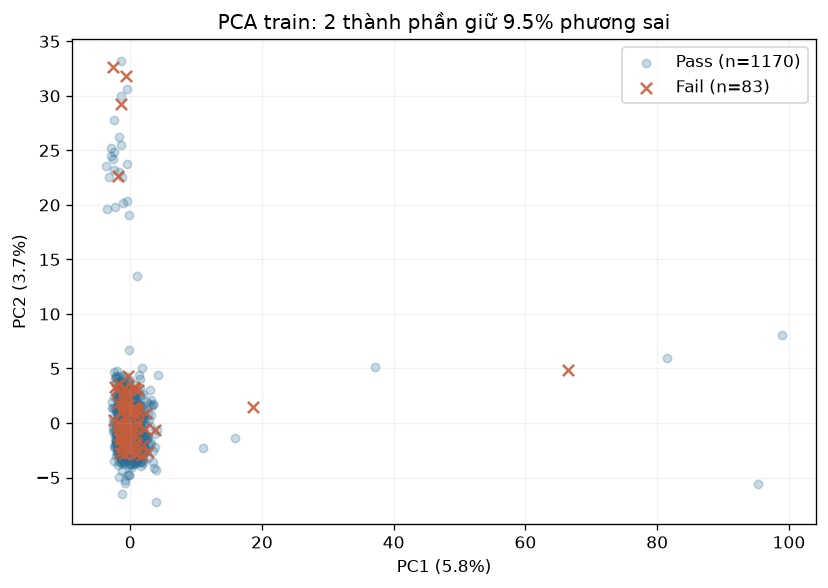

In [4]:
pca_diagnostic = PCA(n_components=2, random_state=SPLIT_SEED)
train_projection = pca_diagnostic.fit_transform(X_train_diagnostic)
pca_variance = pca_diagnostic.explained_variance_ratio_
fig, ax = plt.subplots(figsize=(7, 5))
for label, color, marker, alpha in [(0, "#2A6F97", "o", 0.25), (1, "#C65D3B", "x", 0.9)]:
    mask = y_train.to_numpy() == label
    ax.scatter(train_projection[mask, 0], train_projection[mask, 1],
               c=color, marker=marker, alpha=alpha, s=25 if label == 0 else 45,
               label=f"{'Fail' if label else 'Pass'} (n={int(mask.sum())})")
ax.set(
    title=f"PCA train: 2 thành phần giữ {pca_variance.sum():.1%} phương sai",
    xlabel=f"PC1 ({pca_variance[0]:.1%})", ylabel=f"PC2 ({pca_variance[1]:.1%})",
)
ax.legend()
ax.grid(alpha=0.15)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "train_pca_projection.png", dpi=170, bbox_inches="tight")
plt.show()

## 7. Ba mô hình, imbalance và lưới tham số đã định trước

### XGBoost GPU

XGBoost học lần lượt các cây boosting để bổ sung cho mô hình trước đó. Lưới thử độ sâu 2/3 và `min_child_weight` 1/5; cấu hình hạn chế độ phức tạp và regularization nhằm kiểm soát học nhiễu. Nhiều round hơn không tự bảo đảm chất lượng tốt hơn.

XGBoost dùng `scale_pos_weight = n_{Pass}/n_{Fail}` tính từ **nhãn của chính lần fit**: train-pilot có tỷ lệ riêng; refit fold và refit toàn train tính lại tương ứng. Nó tăng ảnh hưởng của lớp Fail khi học, không sinh thêm sản phẩm lỗi. Pilot theo dõi đúng AP của scikit-learn và **tối đa hóa AP**; xem mục 15.

### Logistic Regression L1

LR tạo score qua hàm logistic $\sigma(\beta_0+x^T\beta)$. Dạng mục tiêu học là log-loss có trọng số cộng phạt L1 $\lambda\sum_j|\beta_j|$. L1 có thể làm một số hệ số về 0; đây là lựa chọn đặc trưng bên trong mô hình LR, không phải SelectKBest áp chung cho ba mô hình.

`C` điều khiển ngược mức regularization: **C nhỏ → ràng buộc mạnh hơn**, có thể bớt học nhiễu nhưng cũng bỏ lỡ tín hiệu. C lớn hơn cho mô hình linh hoạt hơn. Dùng solver **liblinear**, L1 (`l1_ratio=1` trong phiên bản ghi ở metadata), `tol=1e-3`, tối đa **5.000 iteration**; số iteration thực tế được báo, không giả định luôn chạy đủ giới hạn.

### RandomForestClassifier có trọng số lớp

RF gồm **300 cây**, kết hợp các cây được học với bootstrap và tập đặc trưng ngẫu nhiên (`max_features="sqrt"`). Thử giới hạn độ sâu và kích thước lá. Đây là `RandomForestClassifier(class_weight="balanced")`, **không phải BalancedRandomForest** và không có bước SMOTE/oversampling riêng.

LR và RF đều dùng trọng số lớp:

$$
w_c=\frac{N_{fit}}{K\,N_{c,fit}},\qquad K=2.
$$

Trên toàn bộ train, mỗi Fail có trọng số khoảng **14,1 lần** mỗi Pass; trong fold thì tính lại. **14,1 là từ tỷ lệ lớp, không phải chi phí FN = 10.** Ma trận chi phí không tự đổi `class_weight` thành `{0:1, 1:10}`. Trọng số tác động cách học; AP/chi phí tác động việc lựa chọn cấu hình/ngưỡng.

| Mô hình | Các cấu hình thử | Thiết lập giữ cố định |
|---|---|---|
| XGBoost | depth = 2/3 × child weight = 1/5: **4** | `cuda:0`, hist, learning rate 0,05; lambda 5; alpha 0,1; subsample/colsample 0,8; max bin 128; cap 1.000 round, patience 50 |
| LR L1 | C = 0,01/0,1/1: **3** | liblinear, L1, balanced, max_iter 5.000, tol 0,001, CPU |
| RF | depth = 5/None × leaf = 1/5: **4** | 300 cây, sqrt, balanced, `n_jobs=4`, CPU |

Mỗi seed thử 11 cấu hình; 5 seed tạo **55 kết quả tìm kiếm cấu hình**. 5-fold OOF tương ứng **275 lần fit mô hình fold**. XGBoost cần thêm **100 pilot** (4 cấu hình × 5 fold × 5 seed), rồi **15 fit cuối** trên toàn train: tổng **390 lần fit classifier** theo mặc định hiện tại. Pilot đã tách riêng, không được tính lẫn thành các run test; test chỉ có **15 run**.

Không mặc định XGBoost phải thắng vì có GPU hoặc boosting. GPU phục vụ tính toán; kết quả phụ thuộc dữ liệu, biểu diễn, cấu hình và cách đánh giá.


In [5]:
experiment_start = time.perf_counter()
experiment = run_experiment(
    X_train, y_train, X_test, y_test,
    seeds=EXPERIMENT_SEEDS,
    output_dir=OUTPUT_DIR,
    split_seed=SPLIT_SEED,
    verbose=True,
)
experiment_seconds = time.perf_counter() - experiment_start

results = experiment["results"].copy()
predictions = experiment["predictions"].copy()
oof_predictions = experiment["oof_predictions"].copy()
candidate_search = experiment["candidate_search"].copy()
cv_fold_log = experiment["cv_fold_log"].copy()
learning_history = experiment["learning_history"].copy()
threshold_curves = experiment["threshold_curves"].copy()
summary = experiment["summary"].copy()
development_summary = experiment["development_summary"].copy()
baselines = experiment["baselines"].copy()
policies = experiment["policies"].copy()
metadata = experiment["metadata"]

print(f"Hoàn tất: {experiment_seconds:.1f} giây.")
print("Mô hình:", MODEL_NAMES)
print("Các file kết quả và policy đã được helper lưu trong:", OUTPUT_DIR)
print("Mô hình chọn ở giai đoạn phát triển:", metadata.get("development_winner"))
display(pd.DataFrame([
    {"Nội dung": "Tiêu chí chính", "Giá trị": metadata.get("primary_metric")},
    {"Nội dung": "Chọn siêu tham số", "Giá trị": metadata.get("hyperparameter_selection")},
    {"Nội dung": "Số run", "Giá trị": len(results)},
    {"Nội dung": "Thời gian toàn bộ (giây)", "Giá trị": experiment_seconds},
]))

Seed 13 | XGBoost: CV selection


  xgb_d2_w1: OOF AP=0.1685, cost=0.5291


  xgb_d2_w5: OOF AP=0.1611, cost=0.5371


  xgb_d3_w1: OOF AP=0.1707, cost=0.5778


  xgb_d3_w5: OOF AP=0.1706, cost=0.5770


  Frozen: xgb_d3_w1, threshold=0.46763, rounds=12, device=cuda:0


... (78 outputs left out)

  Frozen: rf_d5_leaf5, threshold=0.39959, rounds=0, device=cpu


Completed 15 fixed-holdout evaluations in 205.7s.


Hoàn tất: 206.1 giây.
Mô hình: ('XGBoost', 'LogReg_L1', 'RF_balanced')
Các file kết quả và policy đã được helper lưu trong: D:\AI_Bussiness_Huflit\Đồ án cuối\artifacts\three_model_five_seeds
Mô hình chọn ở giai đoạn phát triển: RF_balanced


,Nội dung,Giá trị
0,Tiêu chí chính,expected_cost
1,Chọn siêu tham số,Highest pooled training-OOF sklearn Average Pr...
2,Số run,15
3,Thời gian toàn bộ (giây),206.089979


## 8. Các kiểm tra tự động đang xác nhận điều gì?

Code kiểm tra đủ **15 cặp seed/model**, mỗi cặp có **314 dự đoán test** và **1.253 dự đoán OOF train**. Vì cùng sản phẩm được dự đoán nhiều lần, file test có $15\times314=4.710$ dòng ghi nhận, nhưng chỉ 314 sản phẩm duy nhất. Tương tự, file OOF có $15\times1253=18.795$ dòng ghi nhận.

Các assertion còn kiểm tra:

- Không trùng khóa `(seed, model, row_index)`; nhãn đúng thứ tự và score hữu hạn trong [0,1].
- Mỗi run có $TP+FP+FN+TN=314$ và $TP+FN=21$; không cộng năm seed thành một ma trận test mới.
- $BER+BalancedAccuracy=1$; số kiểm tra bằng TP + FP; EC và EMC error-only đúng công thức khác nhau.
- Ngưỡng dùng chấm test khớp policy đã lưu trước đó.

Đạt các kiểm tra này nghĩa là dữ liệu kết quả và phép tính nhất quán. Nó không tự chứng minh mô hình đủ tốt cho doanh nghiệp hoặc test là dữ liệu độc lập hoàn toàn mới. Tách fold và pilot còn có dấu vết trong `cv_split_manifest.json` và log fit để kiểm tra thêm.


In [6]:
assert len(results) == 15
assert set(results["seed"]) == set(EXPERIMENT_SEEDS)
assert set(results["model"]) == set(MODEL_NAMES)
assert not results.duplicated(["seed", "model"]).any()
assert len(predictions) == 15 * len(y_test) == 4710
assert len(oof_predictions) == 15 * len(y_train) == 18795
assert len(candidate_search) == 5 * 11 == 55
assert len(cv_fold_log) == 5 * 11 * 5 == 275
assert not predictions.duplicated(["seed", "model", "row_index"]).any()
assert not oof_predictions.duplicated(["seed", "model", "row_index"]).any()

for (seed, model), group in predictions.groupby(["seed", "model"]):
    assert len(group) == len(y_test)
    assert set(group["row_index"]) == set(X_test.index)
    assert np.isfinite(group["score"]).all()
    assert group["score"].between(0, 1).all()
    expected_truth = y_test.loc[group["row_index"]].to_numpy()
    assert np.array_equal(group["y_true"].to_numpy(), expected_truth)
for (seed, model), group in oof_predictions.groupby(["seed", "model"]):
    assert len(group) == len(y_train)
    assert set(group["row_index"]) == set(X_train.index)
    assert group["fold"].nunique() == 5

assert results[["tp", "fp", "fn", "tn"]].sum(axis=1).eq(len(y_test)).all()
assert (results["tp"] + results["fn"]).eq(int(y_test.sum())).all()
assert np.allclose(results["balanced_accuracy"] + results["ber"], 1.0)
assert results["n_inspections"].eq(results["tp"] + results["fp"]).all()
assert np.allclose(
    results["expected_cost"], (results["tp"] + results["fp"] + 10 * results["fn"]) / len(y_test)
)
assert np.allclose(results["cost_per_1000"], 1000 * results["expected_cost"])
assert np.allclose(results["emc_error_only"], (results["fp"] + 10 * results["fn"]) / len(y_test))
policy_check = results[["seed", "model", "threshold"]].merge(
    policies[["seed", "model", "threshold"]], on=["seed", "model"],
    suffixes=("_evaluated", "_frozen"), validate="one_to_one",
)
assert len(policy_check) == 15
assert np.allclose(policy_check["threshold_evaluated"], policy_check["threshold_frozen"])
print("Đạt kiểm tra 15 run, dự đoán mỗi mẫu, ngưỡng policy và phép tính chi phí.")

Đạt kiểm tra 15 run, dự đoán mỗi mẫu, ngưỡng policy và phép tính chi phí.


## 9. Kết quả từng run: đọc chỉ số cùng số đếm

Bảng dưới có đủ **15 run test**, dùng cấu hình và ngưỡng đã chốt từ OOF-train. Không chọn ngưỡng hoặc seed lại theo bảng này. Lớp dương là Fail = 1.

| Chỉ số | Công thức | Câu hỏi nó trả lời |
|---|---|---|
| Accuracy | $(TP+TN)/N$ | Bao nhiêu sản phẩm được phân loại đúng tổng thể? |
| Precision Fail | $TP/(TP+FP)$ | Trong số bị gắn Fail, bao nhiêu thực sự lỗi? |
| Recall / TPR | $TP/(TP+FN)$ | Trong các sản phẩm lỗi, tìm được bao nhiêu? |
| F1 Fail | $2TP/(2TP+FP+FN)$ | Tổng hợp Precision và Recall của Fail. |
| Specificity / TNR | $TN/(TN+FP)$ | Trong các sản phẩm tốt, nhận đúng bao nhiêu? |
| FPR | $FP/(TN+FP)=1-TNR$ | Tỷ lệ sản phẩm tốt bị báo lỗi nhầm. |
| FNR | $FN/(TP+FN)=1-Recall$ | Tỷ lệ lỗi bị bỏ sót. |
| Balanced Accuracy | $(TPR+TNR)/2$ | Trung bình khả năng nhận đúng hai lớp. |
| BER | $(FNR+FPR)/2=1-BA$ | Trung bình hai tỷ lệ sai, càng thấp càng tốt. |
| G-mean | $\sqrt{TPR\times TNR}$ | Trung bình nhân khả năng nhận đúng hai lớp. |
| Inspection/alarm rate | $(TP+FP)/N$ | Tỷ lệ sản phẩm phải kiểm tra lại theo quy trình giả định. |

MCC tổng hợp cả bốn ô, nằm trong [-1,1]: +1 là phân loại đúng hoàn toàn, 0 không cho thấy tương quan nhãn hữu ích theo thước đo này, −1 là nhãn đối nghịch hoàn toàn:

$$
MCC=\frac{TP\,TN-FP\,FN}{\sqrt{(TP+FP)(TP+FN)(TN+FP)(TN+FN)}}.
$$

Code dùng quy ước Precision/F1 = 0 khi mẫu số bằng 0; MCC dùng quy ước của scikit-learn. Recall/FPR có mẫu số dương vì test có cả hai lớp. AP và PR-AUC không tính từ một ma trận nhầm lẫn duy nhất; xem mục 12.

Mốc **luôn Pass** không kiểm tra gì nhưng bỏ sót 21 Fail: tổng chi phí $10\times21=210$, EC $210/314\approx0,66879$. Mốc **gán Fail tất cả** kiểm tra 314 sản phẩm: EC = 1. Hai mốc giúp tránh chọn một mô hình phức tạp nhưng còn tốn hơn quyết định đơn giản.

Không nhìn một chỉ số đơn lẻ: Recall tăng có thể đi cùng nhiều FP; Precision cao có thể đi cùng bỏ sót nhiều Fail. Tiêu chí chính của bài thử này là EC theo ma trận đã thống nhất, còn các chỉ số khác giải thích đánh đổi.


In [7]:
metric_columns = [
    "seed", "model", "threshold", "average_precision", "pr_auc_trapezoid",
    "precision", "recall", "f1", "balanced_accuracy", "ber",
    "expected_cost", "cost_per_1000", "n_inspections", "tp", "fp", "fn", "tn",
]
display(results.sort_values(["model", "seed"])[metric_columns].round(5))
print("Mốc tham chiếu trên cùng tập test:")
baseline_columns = [
    column for column in [
        "model", "policy", "baseline", "accuracy", "average_precision",
        "precision", "recall", "expected_cost", "cost_per_1000",
        "n_inspections", "tp", "fp", "fn", "tn",
    ] if column in baselines.columns
]
display(baselines[baseline_columns].round(5))

,seed,model,threshold,average_precision,pr_auc_trapezoid,precision,recall,f1,balanced_accuracy,ber,expected_cost,cost_per_1000,n_inspections,tp,fp,fn,tn
1,13,LogReg_L1,0.61293,0.17731,0.16727,0.14286,0.23810,0.17857,0.56785,0.43215,0.62102,621.01911,35,5,30,16,263
4,42,LogReg_L1,0.53189,0.14387,0.13152,0.10976,0.42857,0.17476,0.58971,0.41029,0.64331,643.31210,82,9,73,12,220
7,123,LogReg_L1,0.51994,0.14387,0.13152,0.13725,0.66667,0.22764,0.68316,0.31684,0.54777,547.77070,102,14,88,7,205
10,2024,LogReg_L1,0.40015,0.17720,0.16718,0.12500,0.42857,0.19355,0.60678,0.39322,0.61146,611.46497,72,9,63,12,230
13,2026,LogReg_L1,0.53413,0.14387,0.13152,0.11392,0.42857,0.18000,0.59483,0.40517,0.63376,633.75796,79,9,70,12,223
2,13,RF_balanced,0.31954,0.20539,0.18180,0.23077,0.28571,0.25532,0.60873,0.39127,0.56051,560.50955,26,6,20,15,273
5,42,RF_balanced,0.46502,0.17935,0.16277,0.29412,0.23810,0.26316,0.59857,0.40143,0.56369,563.69427,17,5,12,16,281
8,123,RF_balanced,0.17000,0.21194,0.19496,0.21739,0.71429,0.33333,0.76499,0.23501,0.41083,410.82803,69,15,54,6,239
11,2024,RF_balanced,0.18667,0.21431,0.18993,0.22222,0.57143,0.32000,0.71404,0.28596,0.45860,458.59873,54,12,42,9,251
14,2026,RF_balanced,0.39959,0.22939,0.20422,0.17647,0.57143,0.26966,0.69015,0.30985,0.50318,503.18471,68,12,56,9,237


Mốc tham chiếu trên cùng tập test:


,policy,accuracy,average_precision,precision,recall,expected_cost,cost_per_1000,n_inspections,tp,fp,fn,tn
0,always_pass,0.93312,0.06688,0.00000,0.0,0.66879,668.78981,0,0,0,21,293
1,review_all,0.06688,0.06688,0.06688,1.0,1.00000,1000.00000,314,21,293,0,0


## 10. Mean ± std của năm run và hai bảng xếp hạng

Với chỉ số m của một họ mô hình qua năm seed:

$$
\bar m=\frac15\sum_{s=1}^{5}m_s,\qquad
SD=\sqrt{\frac{\sum_{s=1}^{5}(m_s-\bar m)^2}{5-1}}.
$$

Đây là mean và **độ lệch chuẩn mẫu (`ddof=1`)** của năm run trên cùng test. Không gộp mọi dòng dự đoán thành các sản phẩm độc lập mới; không diễn giải mean ± SD là khoảng tin cậy 95%. Số kiểm tra trung bình có thể là số lẻ vì đó là trung bình của năm số đếm nguyên.

Kết quả hiện có từ `summary.csv`:

| Mô hình | AP test mean ± SD | PR-AUC hình thang mean ± SD | EC/sản phẩm mean ± SD | Recall mean | F1 mean |
|---|---:|---:|---:|---:|---:|
| XGBoost | 0,142793 ± 0,041902 | 0,127820 ± 0,036499 | 0,608917 ± 0,059683 | 0,295238 | 0,199933 |
| LR L1 | 0,157222 ± 0,018289 | 0,145802 ± 0,019557 | 0,611465 ± 0,037615 | 0,438095 | 0,190904 |
| RF balanced | **0,208076 ± 0,018308** | **0,186737 ± 0,015673** | **0,499363 ± 0,065940** | **0,476190** | **0,288295** |

Trong các kết quả quan sát, RF có mean AP cao nhất và mean EC thấp nhất; F1 trung bình cũng cao nhất ở các ngưỡng riêng đã chốt. Đây là kết luận có điều kiện theo **dữ liệu, lưới cấu hình và ma trận FN=10, TP=FP=1** đang xét, không chứng minh RF luôn tốt hơn mọi thuật toán.

Bảng **OOF phát triển** bên dưới là điểm đã tham gia chọn tham số/ngưỡng nên có thể lạc quan; không phải nested CV. `development_winner = RF_balanced` đã được chốt từ EC OOF trung bình trước khi chấm test. Thứ tự theo test chỉ mô tả kết quả; không dùng để thay đổi winner, lấy một seed đẹp hơn hoặc điều chỉnh ngưỡng.


In [8]:
report_metrics = [
    ("average_precision", "AP"),
    ("pr_auc_trapezoid", "PR-AUC hình thang"),
    ("precision", "Precision Fail"),
    ("recall", "Recall Fail"),
    ("f1", "F1 Fail"),
    ("balanced_accuracy", "Balanced Accuracy"),
    ("ber", "BER"),
    ("expected_cost", "Chi phí / sản phẩm"),
    ("cost_per_1000", "Chi phí / 1.000 sản phẩm"),
    ("n_inspections", "Số kiểm tra"),
]
summary_report = pd.DataFrame({"Mô hình": list(MODEL_NAMES)})
for metric, label in report_metrics:
    indexed = summary.set_index("model")
    summary_report[label] = [
        f"{indexed.loc[model, metric + '_mean']:.4f} ± {indexed.loc[model, metric + '_std']:.4f}"
        for model in MODEL_NAMES
    ]
display(summary_report)

cost_ranking = summary.sort_values("expected_cost_mean")[
    ["model", "n_runs", "expected_cost_mean", "expected_cost_std", "recall_mean", "alarm_rate_mean"]
].reset_index(drop=True)
cost_ranking.insert(0, "Thứ tự chi phí test (mô tả)", np.arange(1, len(cost_ranking) + 1))
ap_ranking = summary.sort_values("average_precision_mean", ascending=False)[
    ["model", "n_runs", "average_precision_mean", "average_precision_std",
     "pr_auc_trapezoid_mean", "pr_auc_trapezoid_std"]
].reset_index(drop=True)
ap_ranking.insert(0, "Thứ tự AP test (mô tả)", np.arange(1, len(ap_ranking) + 1))
display(cost_ranking.round(5))
display(ap_ranking.round(5))
cost_ranking.to_csv(OUTPUT_DIR / "descriptive_test_cost_ranking.csv", index=False, encoding="utf-8-sig")
ap_ranking.to_csv(OUTPUT_DIR / "descriptive_test_ap_ranking.csv", index=False, encoding="utf-8-sig")
print("Lựa chọn phát triển đã đóng băng theo OOF:", metadata.get("development_winner"))
print("OOF phát triển — điểm dùng chọn, không phải ước lượng không thiên lệch:")
display(development_summary.round(5))

,Mô hình,AP,PR-AUC hình thang,Precision Fail,Recall Fail,F1 Fail,Balanced Accuracy,BER,Chi phí / sản phẩm,Chi phí / 1.000 sản phẩm,Số kiểm tra
0,XGBoost,0.1428 ± 0.0419,0.1278 ± 0.0365,0.1731 ± 0.0826,0.2952 ± 0.1321,0.1999 ± 0.0770,0.5845 ± 0.0424,0.4155 ± 0.0424,0.6089 ± 0.0597,608.9172 ± 59.6826,43.2000 ± 31.0677
1,LogReg_L1,0.1572 ± 0.0183,0.1458 ± 0.0196,0.1258 ± 0.0143,0.4381 ± 0.1521,0.1909 ± 0.0217,0.6085 ± 0.0441,0.3915 ± 0.0441,0.6115 ± 0.0376,611.4650 ± 37.6147,74.0000 ± 24.4847
2,RF_balanced,0.2081 ± 0.0183,0.1867 ± 0.0157,0.2282 ± 0.0424,0.4762 ± 0.2048,0.2883 ± 0.0357,0.6753 ± 0.0709,0.3247 ± 0.0709,0.4994 ± 0.0659,499.3631 ± 65.9397,46.8000 ± 24.0562


,Thứ tự chi phí test (mô tả),model,n_runs,expected_cost_mean,expected_cost_std,recall_mean,alarm_rate_mean
0,1,RF_balanced,5,0.49936,0.06594,0.47619,0.14904
1,2,XGBoost,5,0.60892,0.05968,0.29524,0.13758
2,3,LogReg_L1,5,0.61146,0.03761,0.43810,0.23567


,Thứ tự AP test (mô tả),model,n_runs,average_precision_mean,average_precision_std,pr_auc_trapezoid_mean,pr_auc_trapezoid_std
0,1,RF_balanced,5,0.20808,0.01831,0.18674,0.01567
1,2,LogReg_L1,5,0.15722,0.01829,0.14580,0.01956
2,3,XGBoost,5,0.14279,0.04190,0.12782,0.03650


Lựa chọn phát triển đã đóng băng theo OOF: RF_balanced
OOF phát triển — điểm dùng chọn, không phải ước lượng không thiên lệch:


,model,n_runs,average_precision_mean,average_precision_std,pr_auc_trapezoid_mean,pr_auc_trapezoid_std,roc_auc_mean,roc_auc_std,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,balanced_accuracy_mean,balanced_accuracy_std,ber_mean,ber_std,...,n_inspections_mean,n_inspections_std,tp_mean,tp_std,fp_mean,fp_std,fn_mean,fn_std,tn_mean,tn_std,total_cost_mean,total_cost_std,expected_cost_mean,expected_cost_std,cost_per_1000_mean,cost_per_1000_std,emc_error_only_mean,emc_error_only_std,threshold_mean,threshold_std
0,XGBoost,5,0.15016,0.01384,0.14561,0.01395,0.67956,0.02493,0.84070,0.05811,0.18616,0.04107,0.36386,0.11537,0.23487,0.01848,0.61919,0.02525,0.38081,0.02525,...,177.0,91.35644,30.2,9.57601,146.8,82.04694,52.8,9.57601,1023.2,82.04694,705.0,21.35416,0.56265,0.01704,562.64964,17.04242,0.53855,0.02075,0.51074,0.03522
1,LogReg_L1,5,0.14518,0.01106,0.14044,0.01180,0.67108,0.00983,0.76919,0.04767,0.14623,0.00970,0.50602,0.11988,0.22384,0.01521,0.64694,0.03249,0.35306,0.03249,...,290.2,78.85556,42.0,9.94987,248.2,69.23655,41.0,9.94987,921.8,69.23655,700.2,29.71868,0.55882,0.02372,558.81883,23.71802,0.52530,0.03027,0.51981,0.07639
2,RF_balanced,5,0.17706,0.00633,0.17206,0.00532,0.72114,0.02192,0.82634,0.06077,0.19566,0.05268,0.44578,0.10709,0.25986,0.02470,0.64956,0.01796,0.35044,0.01796,...,208.6,93.80725,37.0,8.88819,171.6,84.97235,46.0,8.88819,998.4,84.97235,668.6,10.71448,0.53360,0.00855,533.59936,8.55106,0.50407,0.00857,0.30816,0.12937


## 11. Ma trận nhầm lẫn: seed 42 minh họa, đủ 15 run để kiểm tra

Seed 42 được chọn trước để minh họa thống nhất, **không phải seed có điểm tốt nhất**. Mỗi ma trận có **314 sản phẩm**, 21 Fail và 293 Pass; hàng là thực tế, cột là dự đoán. Ô chéo là đúng, ô ngoài chéo là sai.

| Mô hình, seed 42 | TN | FP | FN | TP | Số kiểm tra |
|---|---:|---:|---:|---:|---:|
| XGBoost | 279 | 14 | 19 | 2 | 16 |
| LR L1 | 220 | 73 | 12 | 9 | 82 |
| RF balanced | 281 | 12 | 16 | 5 | 17 |

Ví dụ RF seed 42: kiểm tra $5+12=17$ sản phẩm, bắt được 5 lỗi và bỏ sót 16 lỗi. Tổng chi phí là $17+10\times16=177$; EC $=177/314\approx0,563694$; chi phí/1.000 sản phẩm khoảng 563,694. Precision $=5/17\approx29,41\%$, Recall $=5/21\approx23,81\%$.

**Đừng nhầm EC 0,563694 của seed 42 với mean EC 0,499363 của RF qua năm seed.** Một run có thể khác đáng kể trung bình. Tương tự, FN = 16 là số sản phẩm bị bỏ sót; FN-cost = 10 là giá trị giả định cho mỗi lần bỏ sót.

Notebook biểu diễn cả 15 ma trận bằng số nguyên ngay sau bảng seed 42. Không chọn một ma trận đẹp để đại diện mọi run, cũng không trình bày ma trận trung bình có số lẻ như thể đó là số sản phẩm thật.


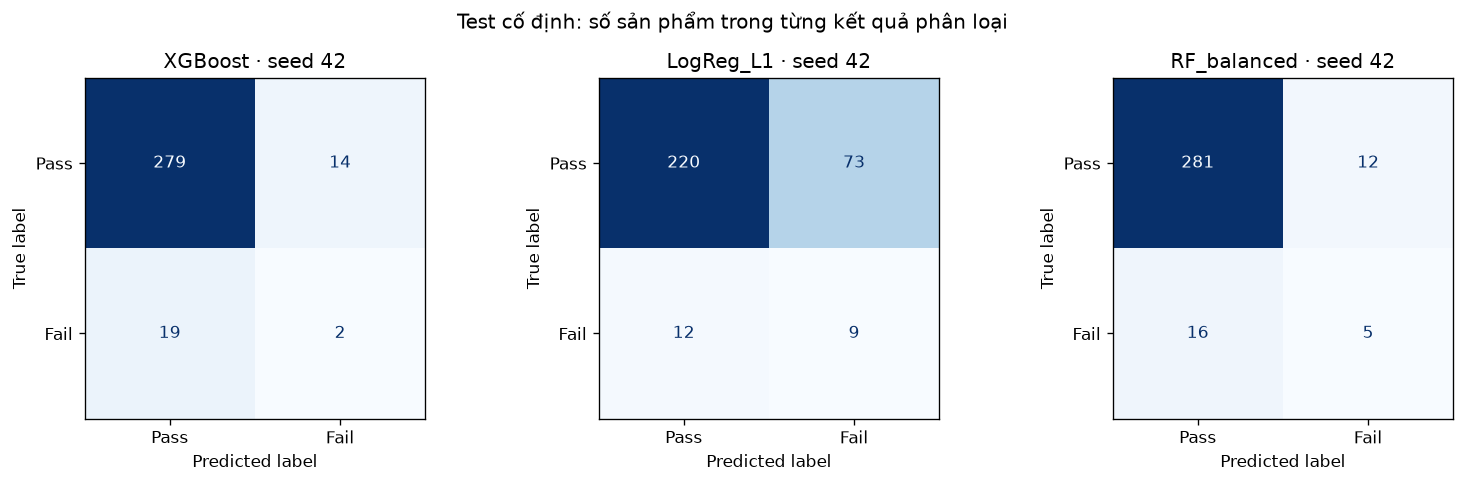

,seed,model,tn,fp,fn,tp
1,13,LogReg_L1,263,30,16,5
2,13,RF_balanced,273,20,15,6
0,13,XGBoost,221,72,13,8
4,42,LogReg_L1,220,73,12,9
5,42,RF_balanced,281,12,16,5
3,42,XGBoost,279,14,19,2
7,123,LogReg_L1,205,88,7,14
8,123,RF_balanced,239,54,6,15
6,123,XGBoost,228,65,12,9
10,2024,LogReg_L1,230,63,12,9


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, model in zip(axes, MODEL_NAMES):
    group = predictions[(predictions["seed"] == DISPLAY_SEED) & (predictions["model"] == model)]
    cm = confusion_matrix(group["y_true"], group["y_pred"], labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=["Pass", "Fail"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d",
    )
    ax.set_title(f"{model} · seed {DISPLAY_SEED}")
fig.suptitle("Test cố định: số sản phẩm trong từng kết quả phân loại")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "confusion_matrices_seed42.png", dpi=170, bbox_inches="tight")
plt.show()

cm_table = results[["seed", "model", "tn", "fp", "fn", "tp"]].sort_values(["seed", "model"]).copy()
for column in ["tn", "fp", "fn", "tp"]:
    cm_table[column] = cm_table[column].astype(int)
display(cm_table)

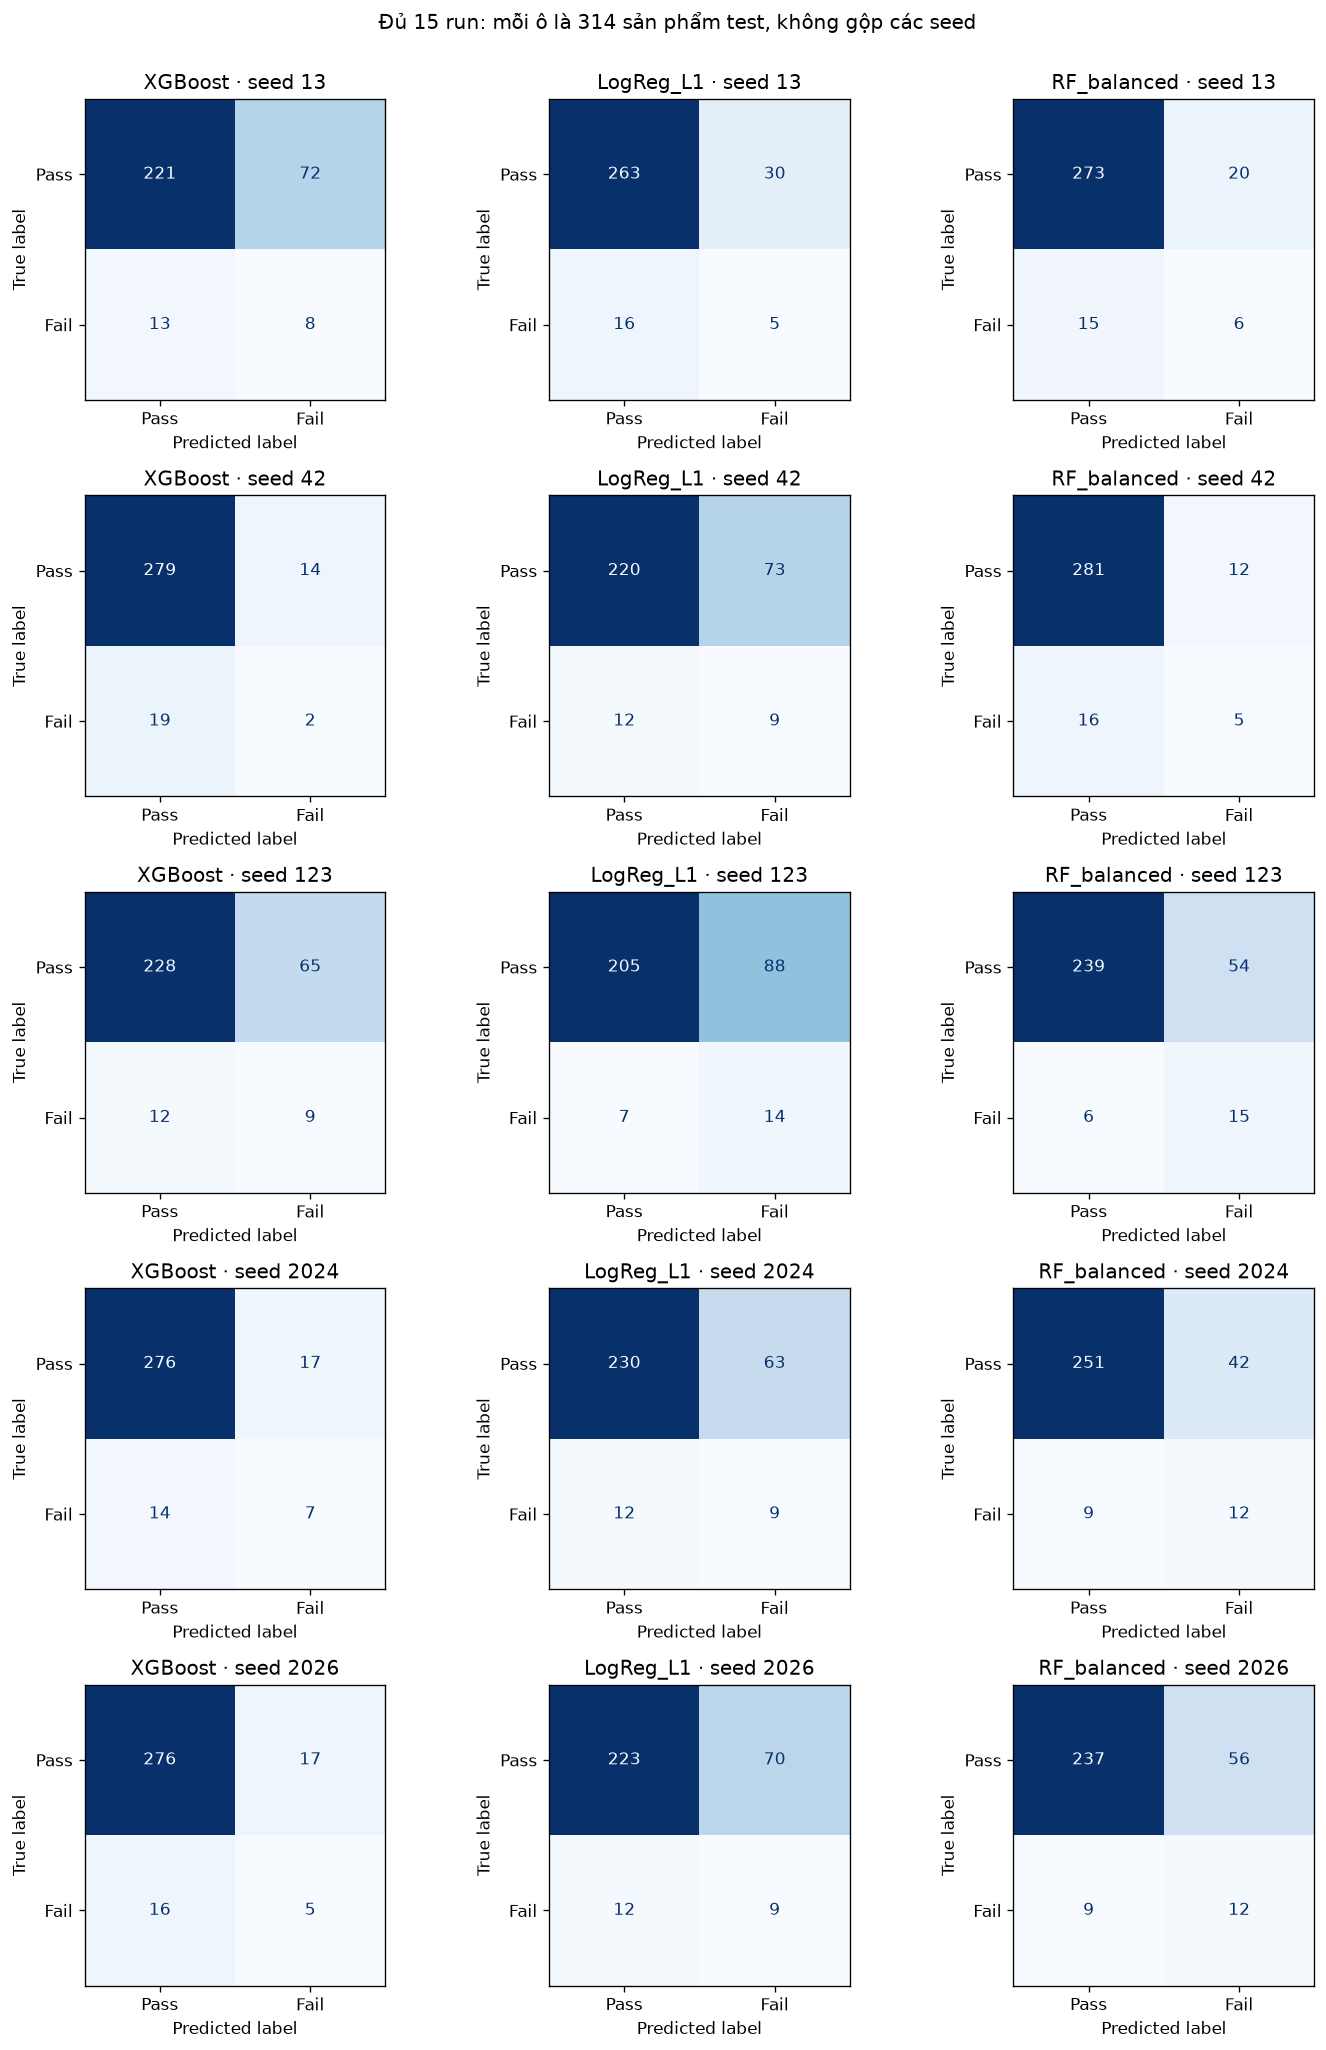

In [10]:
fig, axes = plt.subplots(len(EXPERIMENT_SEEDS), len(MODEL_NAMES), figsize=(12, 17))
for row_position, seed in enumerate(EXPERIMENT_SEEDS):
    for column_position, model in enumerate(MODEL_NAMES):
        group = predictions[(predictions["seed"] == seed) & (predictions["model"] == model)]
        cm = confusion_matrix(group["y_true"], group["y_pred"], labels=[0, 1])
        ax = axes[row_position, column_position]
        ConfusionMatrixDisplay(cm, display_labels=["Pass", "Fail"]).plot(
            ax=ax, cmap="Blues", colorbar=False, values_format="d",
        )
        ax.set_title(f"{model} · seed {seed}")
fig.suptitle("Đủ 15 run: mỗi ô là 314 sản phẩm test, không gộp các seed", y=1.002)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "confusion_matrices_all_15_runs.png", dpi=150, bbox_inches="tight")
plt.show()

## 12. AP và PR-AUC hình thang: hai cách tính khác nhau

Đường Precision–Recall được tạo bằng cách thay ngưỡng trên cùng score. Mỗi điểm thể hiện một cặp Precision/Recall. Đường gần góc trên phải thường tốt hơn; đường ngang là tỷ lệ Fail của test $21/314\approx0,06688$, một mốc tham chiếu theo tỷ lệ lớp, không phải yêu cầu doanh nghiệp.

**Average Precision (AP)** dùng `average_precision_score`. Nếu các mức Recall được sắp tăng dần:

$$
AP=\sum_i(R_i-R_{i-1})P_i.
$$

AP cộng Precision của từng đoạn với trọng số là phần Recall tăng thêm; không nội suy tuyến tính giữa các điểm. Đây là chỉ số dùng chọn cấu hình OOF và cũng là metric early stopping XGBoost trong thử nghiệm.

**PR-AUC hình thang** dùng `auc(recall, precision)` từ `precision_recall_curve`. Với các điểm được sắp theo Recall tăng dần, nó tương ứng:

$$
PR\text{-}AUC_{trap}=\sum_i(R_i-R_{i-1})\frac{P_i+P_{i-1}}2.
$$

Cách này nối tuyến tính các điểm để tính hình thang. Vì quy tắc nội suy khác nhau, AP và PR-AUC hình thang có thể khác dù cùng score. Không đổi tên AP thành PR-AUC rồi coi chúng là cùng một con số. Trong code, `auc` xử lý thứ tự Recall do thư viện trả về.

Ví dụ mean RF: **AP = 0,208076**, còn **PR-AUC hình thang = 0,186737**. AP này không có nghĩa Accuracy 20,8% hay chỉ tìm được 20,8% lỗi. Mỗi mô hình có năm đường từ cùng test; seed 42 được vẽ đậm theo lựa chọn đã khai báo, không vì điểm cao nhất. Ngưỡng vận hành vẫn là ngưỡng OOF đã chốt trước.


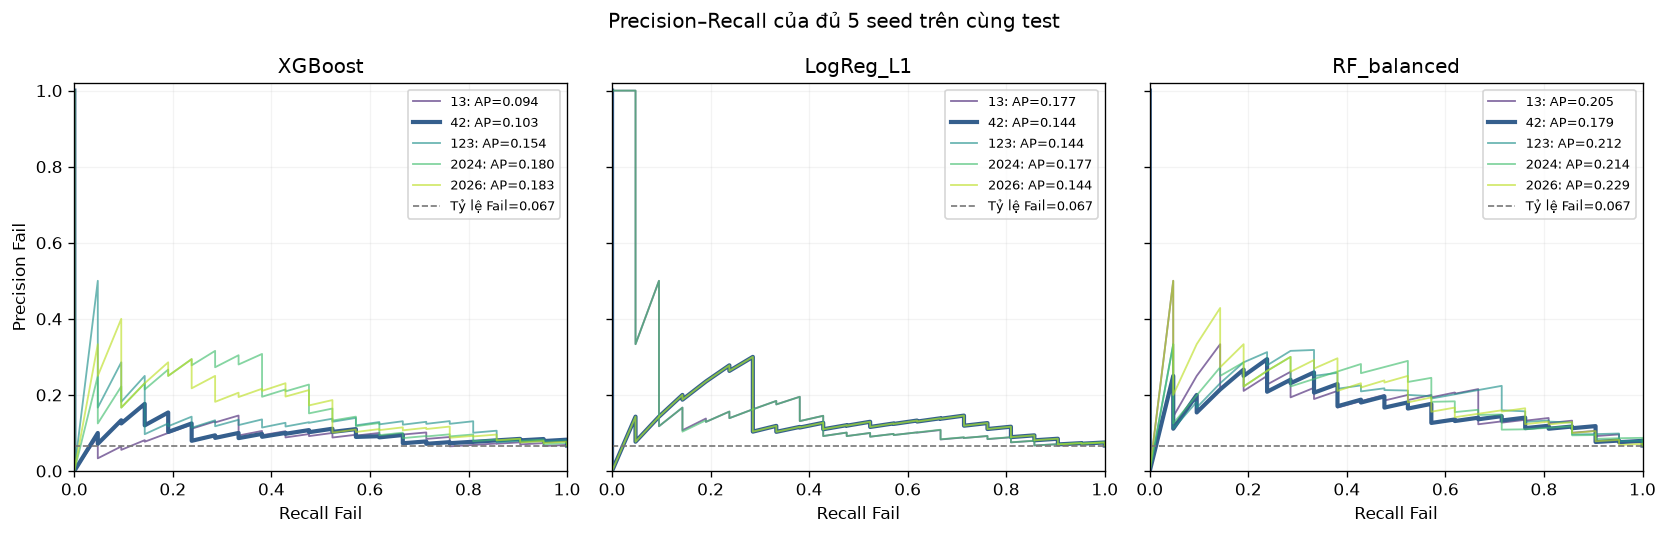

In [11]:
seed_colors = dict(zip(EXPERIMENT_SEEDS, plt.cm.viridis(np.linspace(0.1, 0.9, len(EXPERIMENT_SEEDS)))))
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharex=True, sharey=True)
for ax, model in zip(axes, MODEL_NAMES):
    for seed in EXPERIMENT_SEEDS:
        group = predictions[(predictions["seed"] == seed) & (predictions["model"] == model)]
        precision_curve, recall_curve, _ = precision_recall_curve(group["y_true"], group["score"])
        measured_ap = average_precision_score(group["y_true"], group["score"])
        ax.plot(recall_curve, precision_curve, color=seed_colors[seed],
                linewidth=2.5 if seed == DISPLAY_SEED else 1.1,
                alpha=1.0 if seed == DISPLAY_SEED else 0.65,
                label=f"{seed}: AP={measured_ap:.3f}")
    ax.axhline(float(y_test.mean()), color="#777777", linestyle="--", linewidth=1,
               label=f"Tỷ lệ Fail={y_test.mean():.3f}")
    ax.set(title=model, xlabel="Recall Fail", xlim=(0, 1), ylim=(0, 1.02))
    ax.grid(alpha=0.15)
    ax.legend(fontsize=8)
axes[0].set_ylabel("Precision Fail")
fig.suptitle("Precision–Recall của đủ 5 seed trên cùng test")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "test_precision_recall_five_seeds.png", dpi=170, bbox_inches="tight")
plt.show()

## 13. Phân bố score: vì sao đổi ngưỡng làm đổi FP/FN?

Histogram hiển thị score của Pass và Fail cho seed 42. Mỗi lớp được chuẩn hóa theo mật độ riêng (`density=True`), nên độ cao cột **không phải số lượng sản phẩm** và không được dùng để suy ra hai lớp nhiều bằng nhau. Test thực tế có 293 Pass và chỉ 21 Fail.

Đường dọc là ngưỡng đã chọn từ OOF của chính mô hình/seed đó. Score bên phải ngưỡng được gán Fail; bên trái được gán Pass. Khi hai phân bố chồng lấn, hạ ngưỡng có thể bắt thêm Fail đồng thời tăng FP; nâng ngưỡng có thể giảm số kiểm tra nhưng tăng FN.

Các score dùng class weighting/boosting chưa được xác nhận là xác suất đã hiệu chỉnh. Score 0,3 không mặc định nghĩa là 30% khả năng lỗi thật. Sự chồng lấn mô tả mô hình đang xét; chưa đủ để quy kết dữ liệu vốn không học được hoặc cảm biến nào gây lỗi sản phẩm.


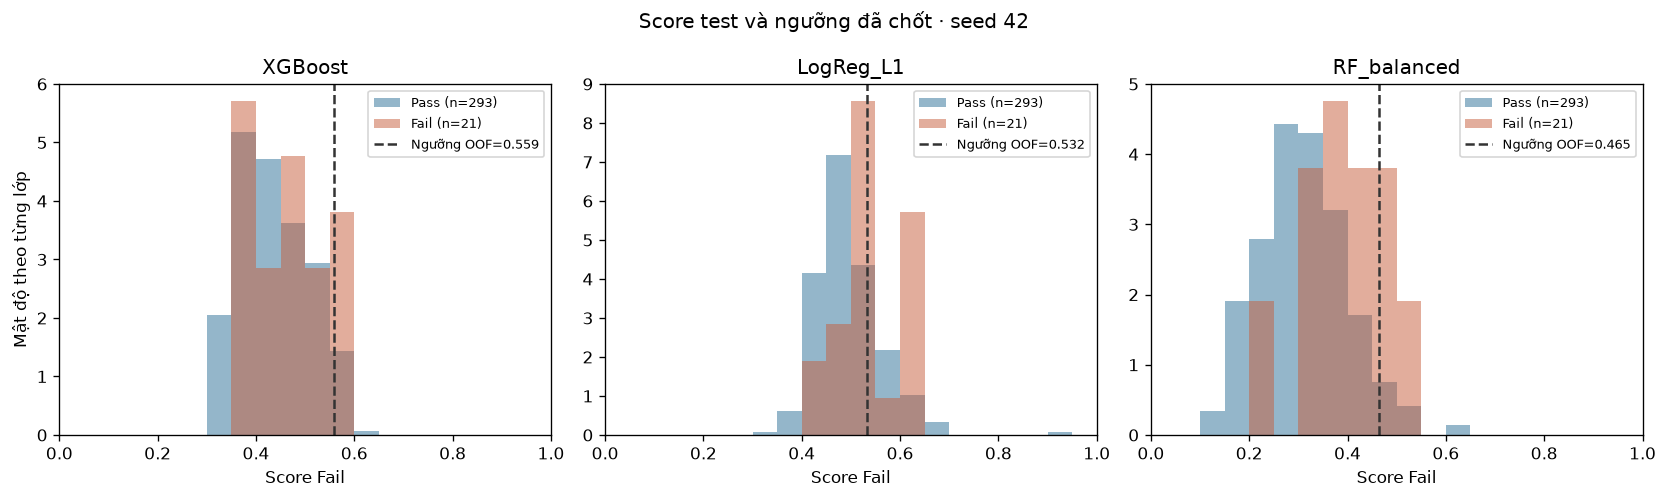

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharex=True)
for ax, model in zip(axes, MODEL_NAMES):
    group = predictions[(predictions["seed"] == DISPLAY_SEED) & (predictions["model"] == model)]
    for true_label, color in [(0, "#2A6F97"), (1, "#C65D3B")]:
        values = group.loc[group["y_true"].eq(true_label), "score"].to_numpy()
        ax.hist(values, bins=np.linspace(0, 1, 21), density=True, alpha=0.5,
                color=color, label=f"{'Fail' if true_label else 'Pass'} (n={len(values)})")
    threshold = float(results.loc[
        results["seed"].eq(DISPLAY_SEED) & results["model"].eq(model), "threshold"
    ].iloc[0])
    if threshold <= 1:
        ax.axvline(threshold, color="#333333", linestyle="--", label=f"Ngưỡng OOF={threshold:.3f}")
    else:
        ax.text(0.98, 0.95, "Policy luôn Pass", ha="right", va="top", transform=ax.transAxes)
    ax.set(title=model, xlabel="Score Fail", xlim=(0, 1))
    ax.legend(fontsize=8)
axes[0].set_ylabel("Mật độ theo từng lớp")
fig.suptitle(f"Score test và ngưỡng đã chốt · seed {DISPLAY_SEED}")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "test_score_overlap_seed42.png", dpi=170, bbox_inches="tight")
plt.show()

## 14. Độ nhạy theo seed: báo đủ năm run

Mỗi điểm là một run đã định trước. Hình thoi và thanh sai số là **mean ± SD**, với `ddof=1`, không phải khoảng tin cậy. Các đường ngang chỉ các mốc luôn Pass/kiểm tra tất cả theo cùng ma trận chi phí.

Seed làm đổi fold CV, bootstrap của RF và các yếu tố ngẫu nhiên khác, nên cấu hình/round/ngưỡng được chọn cũng có thể đổi. Test và nhãn test vẫn giữ nguyên. Các run không độc lập về dữ liệu; không dùng SD này như bằng chứng đã kiểm chứng trên năm nhà máy hoặc năm tập test khác nhau.

Bảng min/max ngưỡng và chi phí mô tả độ dao động, không dùng để chọn lại seed ít tốn nhất sau khi nhìn test. Phân bố score và ngưỡng của các mô hình khác nhau; ngưỡng cao hơn không tự nghĩa mô hình tốt hơn hoặc xác suất đã đáng tin cậy hơn.


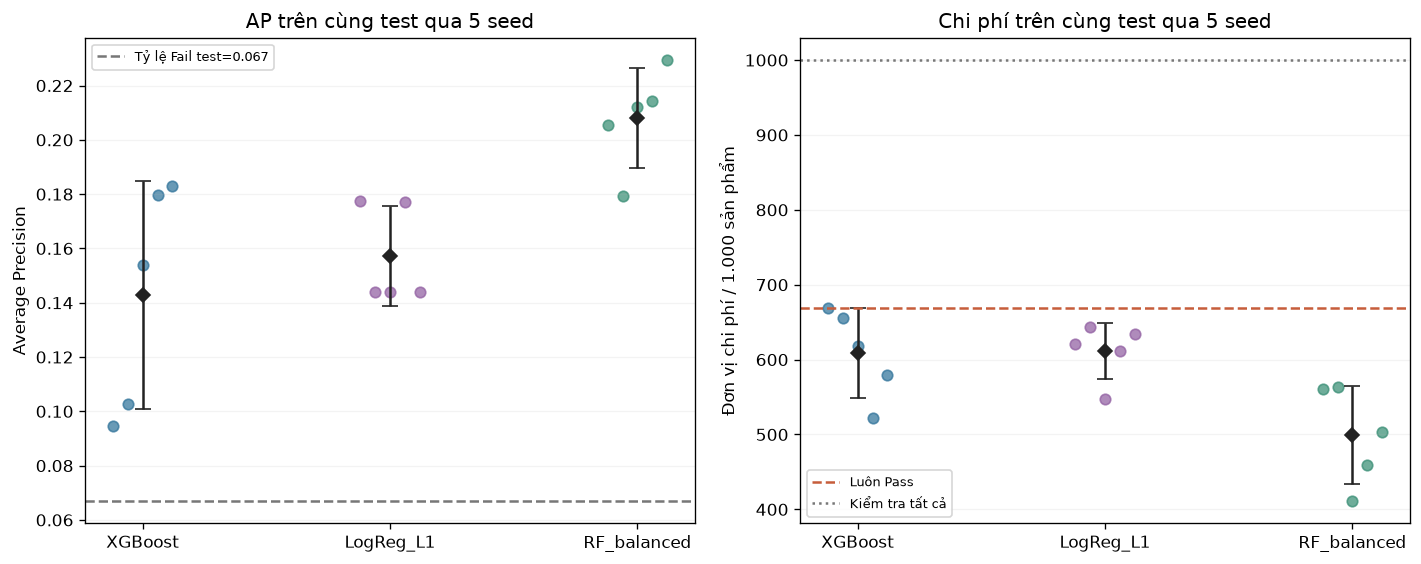

,threshold_mean,threshold_std,threshold_min,threshold_max,test_cost_min,test_cost_max
model,,,,,,
XGBoost,0.51074,0.03522,0.46763,0.55866,0.52229,0.66879
LogReg_L1,0.51981,0.07639,0.40015,0.61293,0.54777,0.64331
RF_balanced,0.30816,0.12937,0.17000,0.46502,0.41083,0.56369


Khoảng min/max chỉ mô tả độ dao động, không dùng để chọn seed tốt nhất.


In [13]:
model_colors = dict(zip(MODEL_NAMES, ["#2A6F97", "#8E5A9F", "#328A70"]))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for model_index, model in enumerate(MODEL_NAMES):
    rows = results[results["model"].eq(model)].set_index("seed").loc[list(EXPERIMENT_SEEDS)]
    offsets = np.linspace(-0.12, 0.12, len(EXPERIMENT_SEEDS))
    for ax, metric in zip(axes, ["average_precision", "cost_per_1000"]):
        values = rows[metric].to_numpy()
        ax.scatter(model_index + offsets, values, s=40, color=model_colors[model], alpha=0.7)
        ax.errorbar(model_index, values.mean(), yerr=values.std(ddof=1),
                    fmt="D", color="#222222", capsize=5, markersize=6)
axes[0].axhline(float(y_test.mean()), color="#777777", linestyle="--",
                label=f"Tỷ lệ Fail test={y_test.mean():.3f}")
axes[1].axhline(1000 * 10 * float(y_test.mean()), color="#C65D3B", linestyle="--",
                label="Luôn Pass")
axes[1].axhline(1000, color="#777777", linestyle=":", label="Kiểm tra tất cả")
for ax in axes:
    ax.set_xticks(range(len(MODEL_NAMES)), MODEL_NAMES)
    ax.grid(axis="y", alpha=0.15)
    ax.legend(fontsize=8)
axes[0].set(title="AP trên cùng test qua 5 seed", ylabel="Average Precision")
axes[1].set(title="Chi phí trên cùng test qua 5 seed",
            ylabel="Đơn vị chi phí / 1.000 sản phẩm")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "test_between_seed_variability.png", dpi=170, bbox_inches="tight")
plt.show()

threshold_variability = results.groupby("model", sort=False).agg(
    threshold_mean=("threshold", "mean"), threshold_std=("threshold", "std"),
    threshold_min=("threshold", "min"), threshold_max=("threshold", "max"),
    test_cost_min=("expected_cost", "min"), test_cost_max=("expected_cost", "max"),
)
display(threshold_variability.round(5))
print("Khoảng min/max chỉ mô tả độ dao động, không dùng để chọn seed tốt nhất.")

## 15. Quá trình fit XGBoost và hội tụ LR: đọc đúng log

### XGBoost early stopping bên trong một fold

1. Từ **phần train của fold OOF**, tách stratified **20% làm stop-validation**, 80% làm train-pilot. Fold OOF giữ ngoài cả hai phần.
2. Fit preprocessing chỉ trên train-pilot rồi transform stop-validation. Tính `scale_pos_weight` từ nhãn train-pilot.
3. Fit tối đa **1.000 boosting round**, ghi AP của train-pilot và stop-validation bằng đúng `average_precision_score`. Callback đặt **`maximize=True`** và theo dõi `validation_1` (stop-validation), patience **50 round**.
4. Lấy `best_iteration + 1` làm số round: `best_iteration` là chỉ số bắt đầu từ 0. Sau đó **fit một preprocessor và mô hình mới** trên toàn bộ phần train của fold với số round đã chọn, rồi mới dự đoán fold OOF.
5. Sau khi chọn cấu hình XGBoost, lấy **median best-round của 5 fold**, làm tròn half-up $\lfloor median+0,5\rfloor$ và tối thiểu 1, để fit cuối trên toàn bộ train. Lần fit cuối không dùng test để early stop.

Như vậy, nhãn fold OOF/test không tham gia chọn thời điểm dừng. Đây là pilot nằm trong train, **không biến thiết kế chọn cấu hình 03c thành nested CV**. Score của mô hình refit có thể đổi so với score OOF; ngưỡng OOF không bảo đảm tối ưu trên test.

Đường AP bên dưới minh họa cấu hình được chọn của seed 42 và fold đầu tiên. Nó không phải đường học trên test. Nếu train AP rất cao còn stop AP thấp, có thể có học quá sát train; nếu stop AP dao động, số Fail nhỏ cũng có thể góp phần. Các hình không đủ kết luận nguyên nhân duy nhất. Log `hit_round_cap` cho biết pilot chạm giới hạn tài nguyên; không tự tăng cap sau khi xem test.

### LR L1 và RF

LR liblinear báo số iteration tối ưu thực tế và `ConvergenceWarning`; giới hạn 5.000 không tự bảo đảm hội tụ. API đang dùng không cung cấp chuỗi loss từng iteration, nên notebook không dựng đường loss hoặc “epoch” giả. `nonzero_features` là số hệ số L1 khác 0, không phải bằng chứng nhân quả về cảm biến.

RF có 300 cây; nó không có epoch hay đường loss như mạng neural. GPU chỉ dùng cho XGBoost; log `gpu_device` kiểm tra thiết bị thực sự là CUDA, còn LR/RF là CPU. Thời gian fit là số đo trên máy chạy, không phải cam kết hiệu năng sản xuất.


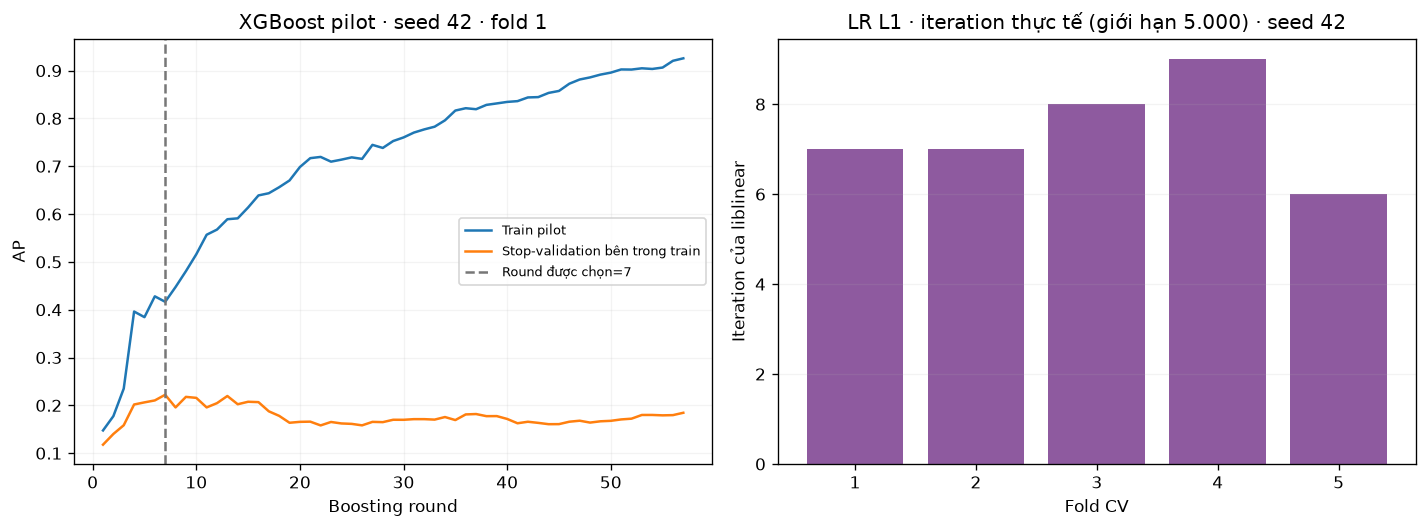

Fit LR cuối trên toàn train:


,seed,iterations,nonzero_features,n_features,fit_seconds
1,13,15,120,466,0.150770
4,42,7,6,466,0.094223
7,123,8,6,466,0.082762
10,2024,13,119,466,0.129275
13,2026,7,6,466,0.116976


XGBoost cuối trên toàn train và thiết bị thực tế:


,seed,boosting_rounds,gpu_device,n_features,fit_seconds
0,13,12,cuda:0,466,0.186777
3,42,12,cuda:0,466,0.157774
6,123,25,cuda:0,466,0.213188
9,2024,105,cuda:0,466,0.389758
12,2026,28,cuda:0,466,0.243669


Số fit LR có cảnh báo hội tụ: 0 / 75
Số pilot XGBoost chạm trần số round: 0 / 100


In [14]:
xgb_selected_id = results.loc[
    results["seed"].eq(DISPLAY_SEED) & results["model"].eq("XGBoost"), "candidate_id"
].iloc[0]
selected_history = learning_history[
    learning_history["seed"].eq(DISPLAY_SEED)
    & learning_history["candidate_id"].eq(xgb_selected_id)
].copy()
assert not selected_history.empty
history_fold = int(selected_history["fold"].min())
selected_history = selected_history[selected_history["fold"].eq(history_fold)].sort_values("round")
pilot_best_round = int(selected_history["best_round"].iloc[0])

lr_selected_id = results.loc[
    results["seed"].eq(DISPLAY_SEED) & results["model"].eq("LogReg_L1"), "candidate_id"
].iloc[0]
selected_lr_log = cv_fold_log[
    cv_fold_log["seed"].eq(DISPLAY_SEED)
    & cv_fold_log["model"].eq("LogReg_L1")
    & cv_fold_log["candidate_id"].eq(lr_selected_id)
].sort_values("fold")
assert len(selected_lr_log) == 5

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(selected_history["round"], selected_history["train_ap"], label="Train pilot")
axes[0].plot(selected_history["round"], selected_history["stop_ap"], label="Stop-validation bên trong train")
axes[0].axvline(pilot_best_round, color="#777777", linestyle="--", label=f"Round được chọn={pilot_best_round}")
axes[0].set(title=f"XGBoost pilot · seed {DISPLAY_SEED} · fold {history_fold}",
            xlabel="Boosting round", ylabel="AP")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.15)
axes[1].bar(selected_lr_log["fold"].astype(int), selected_lr_log["iterations"], color="#8E5A9F")
axes[1].set(title=f"LR L1 · iteration thực tế (giới hạn 5.000) · seed {DISPLAY_SEED}",
            xlabel="Fold CV", ylabel="Iteration của liblinear")
axes[1].set_xticks(selected_lr_log["fold"].astype(int))
axes[1].grid(axis="y", alpha=0.15)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "xgb_pilot_and_lr_iterations_seed42.png", dpi=170, bbox_inches="tight")
plt.show()

print("Fit LR cuối trên toàn train:")
display(results.loc[results["model"].eq("LogReg_L1"), [
    "seed", "iterations", "nonzero_features", "n_features", "fit_seconds",
]].sort_values("seed"))
print("XGBoost cuối trên toàn train và thiết bị thực tế:")
display(results.loc[results["model"].eq("XGBoost"), [
    "seed", "boosting_rounds", "gpu_device", "n_features", "fit_seconds",
]].sort_values("seed"))

lr_all_logs = cv_fold_log[cv_fold_log["model"].eq("LogReg_L1")]
n_lr_warning = int(lr_all_logs["convergence_warning"].fillna(False).astype(bool).sum())
xgb_all_logs = cv_fold_log[cv_fold_log["model"].eq("XGBoost")]
n_xgb_cap = int(xgb_all_logs["hit_round_cap"].fillna(False).astype(bool).sum())
print("Số fit LR có cảnh báo hội tụ:", n_lr_warning, "/", len(lr_all_logs))
print("Số pilot XGBoost chạm trần số round:", n_xgb_cap, "/", len(xgb_all_logs))
if n_lr_warning:
    print("Cần diễn giải thận trọng các cấu hình LR có cảnh báo; không mặc định max_iter lớn là đã hội tụ.")
if n_xgb_cap:
    print("Có pilot chạm trần 1.000 round; đây là giới hạn tài nguyên đã khai báo, không tự tăng sau khi xem test.")

## 16. Ngưỡng chi phí trên OOF: cách chọn và cách đọc đường cong

Với score s và ngưỡng t, quy tắc là **Fail nếu $s\ge t$**, ngược lại Pass. `cost_threshold_curve` lấy các ngưỡng phân biệt từ đường PR, thêm **t = 0** cho gán Fail tất cả và **một t cố định lớn hơn 1** cho luôn Pass. Vì score nằm trong [0,1], t > 1 là ký hiệu cho hành động luôn Pass, không phải xác suất lớn hơn 100%.

`choose_cost_threshold` tính $TP+FP+10FN$ tại từng t và ưu tiên:

1. Tổng chi phí OOF thấp nhất.
2. Nếu hòa, ít lượt kiểm tra TP + FP hơn.
3. Nếu vẫn hòa, ngưỡng cao hơn.

**AP chọn cấu hình, EC chọn ngưỡng:** hai bước có mục tiêu khác nhau. Nếu cấu hình hòa AP thì chi phí OOF và candidate ID mới được dùng để phá hòa. Trong cùng một cấu hình/seed, điểm OOF được dùng lại khi quét t; không fit lại mô hình cho từng ngưỡng. Đổi t làm đổi nhãn/FP/FN nhưng không thay AP hoặc ROC-AUC của chính dãy score đó.

Mỗi mô hình/seed có t riêng. FN-cost = 10 không cho phép suy ra “bỏ sót đúng 10%” hay tự áp **t = 0,1**: score chưa được xác nhận calibration, và ở đây t được chọn thực nghiệm. Các điểm t > 1 được vẽ tại 1,02 chỉ để dễ hiển thị.

Điểm thấp nhất trên đường OOF là **điểm dùng chọn**, có thể lạc quan; không phải chi phí đã xác nhận trên sản phẩm mới. Bảng năm ngưỡng thấp chi phí nhất bên dưới giúp xem vùng tối ưu rộng hay nhạy, không dùng kết quả test để đổi ngưỡng.


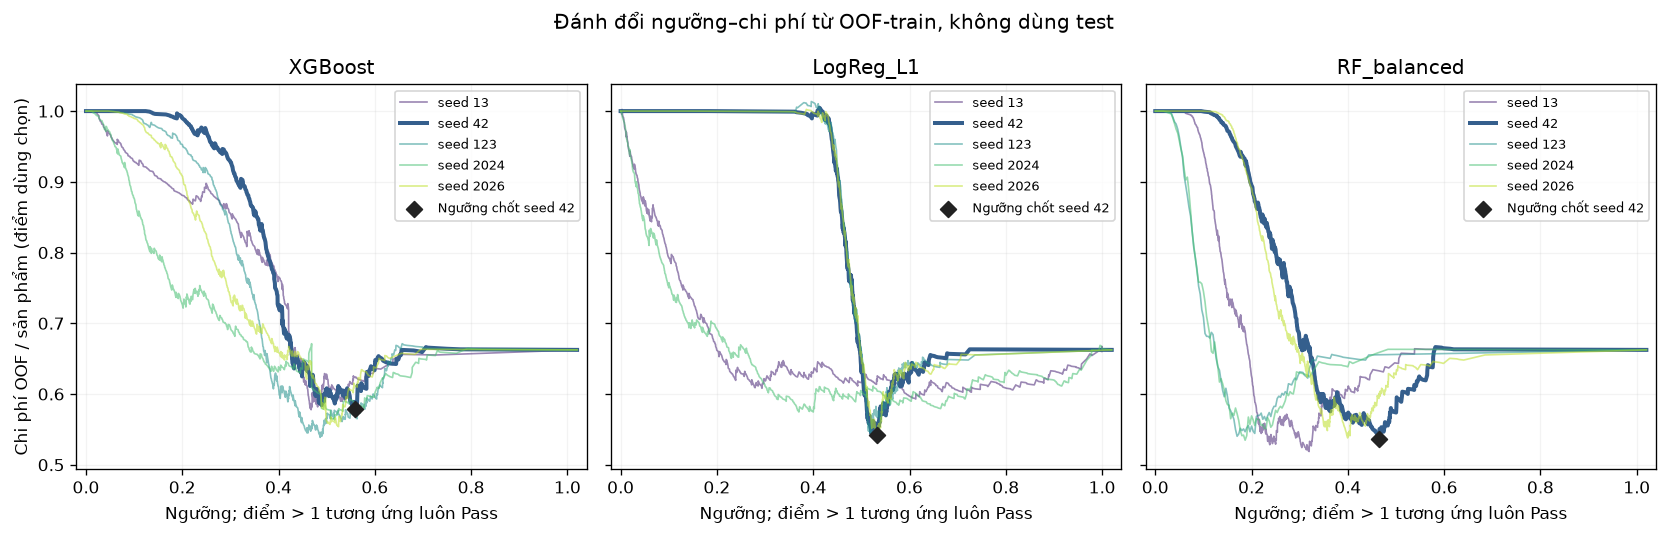

XGBoost · seed 42: 5 phương án chi phí thấp nhất trên OOF dùng chọn


,threshold,expected_cost,precision,recall,n_inspections,tp,fp,fn,tn
4379,0.55866,0.57941,0.19811,0.25301,106,21,85,62,1085
4370,0.55391,0.57941,0.18254,0.27711,126,23,103,60,1067
4378,0.55847,0.58021,0.19626,0.25301,107,21,86,62,1084
4369,0.55387,0.58021,0.18110,0.27711,127,23,104,60,1066
4384,0.56113,0.58101,0.20408,0.24096,98,20,78,63,1092


LogReg_L1 · seed 42: 5 phương án chi phí thấp nhất trên OOF dùng chọn


,threshold,expected_cost,precision,recall,n_inspections,tp,fp,fn,tn
5420,0.53189,0.54270,0.15000,0.54217,300,45,255,38,915
5419,0.53146,0.54350,0.14950,0.54217,301,45,256,38,914
5418,0.53143,0.54429,0.14901,0.54217,302,45,257,38,913
5358,0.52080,0.54429,0.14088,0.61446,362,51,311,32,859
5417,0.53136,0.54509,0.14851,0.54217,303,45,258,38,912


RF_balanced · seed 42: 5 phương án chi phí thấp nhất trên OOF dùng chọn


,threshold,expected_cost,precision,recall,n_inspections,tp,fp,fn,tn
6883,0.46502,0.53631,0.27174,0.3012,92,25,67,58,1103
6882,0.46360,0.53711,0.26882,0.3012,93,25,68,58,1102
6881,0.46328,0.53791,0.26596,0.3012,94,25,69,58,1101
6880,0.46310,0.53871,0.26316,0.3012,95,25,70,58,1100
6879,0.46272,0.53951,0.26042,0.3012,96,25,71,58,1099


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharey=True)
for ax, model in zip(axes, MODEL_NAMES):
    for seed in EXPERIMENT_SEEDS:
        points = threshold_curves[
            threshold_curves["seed"].eq(seed) & threshold_curves["model"].eq(model)
        ].sort_values("threshold")
        shown_x = np.where(points["threshold"].to_numpy() > 1, 1.02, points["threshold"].to_numpy())
        ax.plot(shown_x, points["expected_cost"], color=seed_colors[seed],
                linewidth=2.4 if seed == DISPLAY_SEED else 1,
                alpha=1 if seed == DISPLAY_SEED else 0.55,
                label=f"seed {seed}")
    selected = results[
        results["seed"].eq(DISPLAY_SEED) & results["model"].eq(model)
    ].iloc[0]
    selected_x = 1.02 if selected["threshold"] > 1 else float(selected["threshold"])
    ax.scatter(selected_x, selected["oof_expected_cost"], color="#222222", marker="D",
               s=45, zorder=5, label="Ngưỡng chốt seed 42")
    ax.set(title=model, xlabel="Ngưỡng; điểm > 1 tương ứng luôn Pass", xlim=(-0.02, 1.04))
    ax.grid(alpha=0.15)
    ax.legend(fontsize=8)
axes[0].set_ylabel("Chi phí OOF / sản phẩm (điểm dùng chọn)")
fig.suptitle("Đánh đổi ngưỡng–chi phí từ OOF-train, không dùng test")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "oof_threshold_cost_tradeoff.png", dpi=170, bbox_inches="tight")
plt.show()

for model in MODEL_NAMES:
    near_best = threshold_curves[
        threshold_curves["seed"].eq(DISPLAY_SEED) & threshold_curves["model"].eq(model)
    ].sort_values(["expected_cost", "n_inspections", "threshold"], ascending=[True, True, False])
    print(f"{model} · seed {DISPLAY_SEED}: 5 phương án chi phí thấp nhất trên OOF dùng chọn")
    display(near_best[[
        "threshold", "expected_cost", "precision", "recall",
        "n_inspections", "tp", "fp", "fn", "tn",
    ]].head(5).round(5))

## 17. Cấu hình đã chọn, kết luận và giới hạn

Bảng dưới cho biết mỗi seed đã chọn candidate, ngưỡng, số round/iteration, số hệ số khác 0 và thiết bị nào. **Policy** nghĩa là mô hình đã fit cộng ngưỡng và cách preprocessing đi kèm. Policy cùng `development_winner` được ghi trước bước chấm test; test không cập nhật ngược quyết định đó.

Trong lần chạy này, **RF_balanced được chọn ở giai đoạn phát triển**, đồng thời có chi phí test trung bình thấp nhất và AP test trung bình cao nhất trong ba mô hình đã thử. Mean F1 cũng cao nhất ở các ngưỡng riêng được chọn; điều này không biến RF thành lựa chọn thắng chắc chắn trên mọi dữ liệu hoặc mọi ma trận chi phí.

Với ma trận FN = 10, TP = FP = 1, chi phí RF trung bình khoảng **499,36 đơn vị/1.000 sản phẩm**, so với **668,79** của luôn Pass và **1.000** của kiểm tra tất cả. Chênh lệch tương đối so với luôn Pass khoảng **25,33% theo giả định chi phí đang xét**. Đây không phải 25,33% lợi nhuận, mức giảm lỗi thực tế hoặc khoản tiền tiết kiệm đã xác nhận với doanh nghiệp.

Hiệu quả vẫn còn hạn chế: RF mean Recall khoảng 47,62%, mean Precision khoảng 22,82%; nhiều Fail còn bị bỏ sót và nhiều cảnh báo cần kiểm tra là sản phẩm tốt. Số liệu từng seed và số đếm nguyên cần đi cùng các tỷ lệ. Test chỉ có 21 Fail và đã được xem trong lịch sử dự án, nên chưa đủ để tuyên bố sẵn sàng triển khai.

Ít mẫu Fail, nhiều tương quan, thiếu dữ liệu, lựa chọn biểu diễn/thuật toán và độ chồng lấn score đều là các hướng cần kiểm chứng. Chẩn đoán hiện tại **không chứng minh dữ liệu vốn “xấu” hoặc không thể học được**; PCA 2D hay hệ số mô hình cũng không cho phép kết luận nguyên nhân vật lý của lỗi.

Để chọn policy doanh nghiệp cần chi phí thực tế, quy trình kiểm tra, mức bỏ sót/khối lượng kiểm tra chấp nhận được và dữ liệu xác nhận phù hợp. Không chọn lại mô hình/seed/ngưỡng theo thứ tự test mô tả ở đây. Giữ metadata để phân biệt thay đổi do dữ liệu, phiên bản thư viện, cấu hình và thiết bị.


In [16]:
display(policies[[
    "seed", "model", "candidate_id", "params_json", "threshold",
    "oof_average_precision", "oof_expected_cost", "boosting_rounds",
    "iterations", "nonzero_features", "n_features", "gpu_device",
]].sort_values(["model", "seed"]))

print("Lựa chọn mô hình ở giai đoạn phát triển (OOF, đóng băng trước test):",
      metadata.get("development_winner"))
best_test_cost = summary.loc[summary["expected_cost_mean"].idxmin()]
best_test_ap = summary.loc[summary["average_precision_mean"].idxmax()]
print(
    f"Chi phí test trung bình thấp nhất trong các kết quả quan sát: {best_test_cost['model']} "
    f"= {best_test_cost['expected_cost_mean']:.4f} ± {best_test_cost['expected_cost_std']:.4f} "
    "đơn vị/sản phẩm."
)
print(
    f"AP test trung bình cao nhất: {best_test_ap['model']} "
    f"= {best_test_ap['average_precision_mean']:.4f} ± {best_test_ap['average_precision_std']:.4f}."
)
always_pass_cost = 10 * float(y_test.mean())
if best_test_cost["expected_cost_mean"] < always_pass_cost:
    print("Trong giả định FN=10, TP=FP=1, có mô hình quan sát được chi phí trung bình thấp hơn luôn Pass.")
else:
    print("Trong giả định FN=10, TP=FP=1, chưa thấy mô hình có chi phí trung bình thấp hơn mốc luôn Pass.")
print("Thứ tự test chỉ mang tính mô tả; không chọn lại mô hình, tham số, seed hoặc ngưỡng theo test.")
print("Năm run dùng cùng test 314 sản phẩm, chỉ 21 Fail; std không phải khoảng tin cậy tổng quát.")
print("Chi phí là đơn vị tương đối theo giả định, chưa phải lợi ích kinh tế đã xác nhận.")

metadata_excerpt = {
    key: value for key, value in metadata.items()
    if any(token in key.lower() for token in [
        "version", "gpu", "cuda", "solver", "primary", "selection",
        "seed", "reference", "kaggle", "winner",
    ])
}
print("\nMetadata kiểm tra:")
print(json.dumps(metadata_excerpt, ensure_ascii=False, indent=2, default=str))

,seed,model,candidate_id,params_json,threshold,oof_average_precision,oof_expected_cost,boosting_rounds,iterations,nonzero_features,n_features,gpu_device
1,13,LogReg_L1,lr_l1_c0p1,"{""C"": 0.1}",0.612934,0.130701,0.592977,0,15,120,466,cpu
4,42,LogReg_L1,lr_l1_c0p01,"{""C"": 0.01}",0.531895,0.141212,0.542698,0,7,6,466,cpu
7,123,LogReg_L1,lr_l1_c0p01,"{""C"": 0.01}",0.519942,0.156423,0.542698,0,8,6,466,cpu
10,2024,LogReg_L1,lr_l1_c0p1,"{""C"": 0.1}",0.400155,0.141311,0.574621,0,13,119,466,cpu
13,2026,LogReg_L1,lr_l1_c0p01,"{""C"": 0.01}",0.534127,0.156233,0.541101,0,7,6,466,cpu
2,13,RF_balanced,rf_dNone_leaf5,"{""max_depth"": null, ""min_samples_leaf"": 5, ""n_...",0.319540,0.187146,0.518755,0,0,0,466,cpu
5,42,RF_balanced,rf_d5_leaf5,"{""max_depth"": 5, ""min_samples_leaf"": 5, ""n_est...",0.465020,0.175589,0.536313,0,0,0,466,cpu
8,123,RF_balanced,rf_dNone_leaf1,"{""max_depth"": null, ""min_samples_leaf"": 1, ""n_...",0.170000,0.170590,0.540303,0,0,0,466,cpu
11,2024,RF_balanced,rf_dNone_leaf1,"{""max_depth"": null, ""min_samples_leaf"": 1, ""n_...",0.186667,0.173510,0.534717,0,0,0,466,cpu
14,2026,RF_balanced,rf_d5_leaf5,"{""max_depth"": 5, ""min_samples_leaf"": 5, ""n_est...",0.399592,0.178486,0.537909,0,0,0,466,cpu


Lựa chọn mô hình ở giai đoạn phát triển (OOF, đóng băng trước test): RF_balanced
Chi phí test trung bình thấp nhất trong các kết quả quan sát: RF_balanced = 0.4994 ± 0.0659 đơn vị/sản phẩm.
AP test trung bình cao nhất: RF_balanced = 0.2081 ± 0.0183.
Trong giả định FN=10, TP=FP=1, có mô hình quan sát được chi phí trung bình thấp hơn luôn Pass.
Thứ tự test chỉ mang tính mô tả; không chọn lại mô hình, tham số, seed hoặc ngưỡng theo test.
Năm run dùng cùng test 314 sản phẩm, chỉ 21 Fail; std không phải khoảng tin cậy tổng quát.
Chi phí là đơn vị tương đối theo giả định, chưa phải lợi ích kinh tế đã xác nhận.

Metadata kiểm tra:
{
  "split_seed": 42,
  "experiment_seeds": [
    13,
    42,
    123,
    2024,
    2026
  ],
  "hyperparameter_selection": "Highest pooled training-OOF sklearn Average Precision; tie lower OOF cost, then candidate ID",
  "threshold_selection": "Minimum OOF TP+FP+10*FN; tie fewer inspections, higher threshold",
  "primary_metric": "expected_cost",
  "oof_metrics_ar

## Các tệp kết quả và bản đồ hàm thực thi

Các output được sinh riêng trong `artifacts/three_model_five_seeds/`:

| Tệp | Cách sử dụng |
|---|---|
| `results.csv` | Đủ 15 kết quả test, mỗi hàng là một seed/model. |
| `summary.csv` | Mean/SD test theo mô hình; SD dùng `ddof=1`. |
| `development_summary.csv` | Mean/SD OOF phát triển; đây là điểm tham gia lựa chọn. |
| `predictions.csv`, `oof_predictions.csv` | Score, nhãn, seed/model và chỉ số sản phẩm để kiểm tra từng run. |
| `candidate_search.csv`, `cv_fold_log.csv` | 55 kết quả cấu hình, 275 log fold-refit, hội tụ và thông tin pilot. |
| `learning_history.csv`, `threshold_curves.csv` | AP pilot theo boosting round và chi phí theo ngưỡng OOF. |
| `policies.csv`, `frozen_policies_before_test.json` | Cấu hình/ngưỡng và lựa chọn phát triển đã đóng băng trước test. |
| `cv_split_manifest.json`, `run_metadata.json` | Dấu vết chỉ số chia tập, môi trường, seed, giả định và phiên bản. |
| `baselines.csv`, `train_data_diagnostics.csv` | Các quyết định đơn giản và chẩn đoán train. |
| `descriptive_test_cost_ranking.csv`, `descriptive_test_ap_ranking.csv` | Bảng xếp hạng test chỉ để mô tả, không chọn ngược policy. |
| `models/` | 15 bundle đã fit; mỗi bundle giữ preprocessor và estimator tương ứng. |

Hình được lưu trong `figures/three_model_five_seeds/`. Các tệp sinh riêng không mặc định được commit đầy đủ; muốn có trên máy cần Run All. Notebook đã có output nhúng để đọc trước. Thiếu dữ liệu, kernel hoặc XGBoost/CUDA thì xem hướng dẫn ở mục 3.

Muốn lần theo code, mở [secom_three_model_experiment.py](./secom_three_model_experiment.py):

| Hàm | Vai trò |
|---|---|
| `make_preprocessor` | Xây đúng bốn bước preprocessing, chưa fit. |
| `fit_bundle` | Fit preprocessor + một classifier trên dữ liệu được truyền vào, ghi log thiết bị/hội tụ. |
| `_early_stopping_rounds` | Tách train-pilot/stop-validation bên trong fold train, tìm số boosting round XGBoost. |
| `cost_threshold_curve`, `choose_cost_threshold` | Quét ngưỡng OOF và chọn theo chi phí đã khai báo. |
| `predict_bundle` | Transform bằng preprocessor đã fit, trả score Fail từ estimator đi kèm. |
| `evaluate_scores` | Tính chỉ số, AP/PR-AUC riêng và ma trận chi phí đầy đủ. |
| `run_experiment` | Điều phối 5 seed, CV/chọn/refit, đóng băng policy, sau đó mới chấm test và lưu kết quả. |

Khi dùng một policy, truyền đúng **590 cột thô đúng thứ tự**, dùng bundle và ngưỡng đã lưu; không preprocessing thêm bên ngoài. Notebook không tự cập nhật mô hình dashboard.

**Điểm cần nhớ:** một test cố định; preprocessing học trong fold; pilot XGBoost không dùng fold OOF/test; AP chọn cấu hình, EC chọn ngưỡng; phân biệt AP với PR-AUC; báo đủ năm seed; điểm OOF dùng chọn chưa phải nested CV; chi phí giả định và score chưa calibration cần được diễn giải đúng.
